# Indian Supreme Court Judgment Analytics

**Indian Institute of Information Technology Design and Manufacturing, Kancheepuram**  
**25CS5004 / CS 5010 · Analytics & Systems of Big Data Practice · November 2025 End-Semester Examination**

This notebook combines metadata preprocessing, ten descriptive visualizations, FP-Growth, A-Close, K-Medoids, and a matched PySpark benchmark.

| Analysis | Main result |
| --- | --- |
| Metadata and PDF coverage | 47,400 metadata records, 47,388 exact PDF matches, and 3,843 readable sampled PDFs |
| Association rules | 192 frequent itemsets and 417 rules at 2% support, 50% confidence, and 1.10 minimum lift |
| Closed itemsets | All 192 full-sample itemsets were closed. The 1,000-document prefix reduced 193 frequent sets to 172 closed sets. |
| Text clusters | Five clusters had the highest silhouette among the tested choices. A score of 0.109 indicates weak separation. |
| PySpark | Mining results matched the local implementations. Spark was slower on all tested workloads. |

### Reproduce the analysis

Run from the project folder with `data/judgments.csv` and `data/pdfs/`. Use Python 3.13, Java 17, and the packages in `requirements.txt`. Run the stages in order. The notebook saves figures under `figures/` and analytical outputs under `outputs/`.

The metadata denominator is one CSV row. The mining denominator is one readable PDF, including readable documents without vocabulary matches. The text extractor uses no OCR. The clustering and timing results describe the selected sample and the tested machine.

[Dataset on Kaggle](https://www.kaggle.com/datasets/vangap/indian-supreme-court-judgments) · [Source code on GitHub](https://github.com/thenithin342/supreme-court-judgment-analytics)

## 1. Metadata inventory, cleaning and selection

Establish the full metadata denominator before sampling. Clean textual fields and placeholder identifiers, derive case categories and chronology fields, and report exact PDF matches. Keep repeated diary identifiers and disputed dates available for audit.

In [1]:
from pathlib import Path
import json
import os
import re
import sys
import time
from collections import Counter, defaultdict
from difflib import get_close_matches
from itertools import combinations

import numpy as np
import pandas as pd
import pymupdf as fitz
from IPython.display import display, Image, Markdown

ROOT = Path.cwd()
DATA = ROOT / "data"
OUT = ROOT / "outputs"
FIGURES = ROOT / "figures"
for folder in (OUT, FIGURES):
    folder.mkdir(exist_ok=True)
SEED = 42
MAX_TEXT_CHARS_PER_DOCUMENT = 250_000
MIN_SUPPORT, MIN_CONFIDENCE, MIN_LIFT = 0.02, 0.50, 1.10


def write_json(path, value):
    tmp = path.with_suffix(".tmp")
    tmp.write_text(json.dumps(value, indent=2, ensure_ascii=False), encoding="utf-8")
    tmp.replace(path)


def normalize_document(text):
    return re.sub(r"\s+", " ", text.replace("\x00", " ")).strip()


csv_path = DATA / "judgments.csv"
pdf_dir = DATA / "pdfs"
raw = pd.read_csv(csv_path, dtype="string", keep_default_na=False)
meta = raw.apply(lambda col: col.str.replace(r"\s+", " ", regex=True).str.strip())
for column in meta:
    meta[column] = meta[column].mask(
        meta[column]
        .str.casefold()
        .isin({"", "na", "n/a", "null", "none", "nan", "not available", "-", "--"})
    )
# The archive embeds even the missing diary marker in real filenames.
diary_for_linkage = meta.diary_no.copy()
zero_placeholders = {}
for column in ("diary_no", "case_no"):
    marker = meta[column].str.fullmatch(r"-\s*0", na=False)
    zero_placeholders[column] = int(marker.sum())
    meta[column] = meta[column].mask(marker)
missing = meta.isna().sum().rename("missing")
pd.concat([missing, (100 * missing / len(meta)).rename("percent")], axis=1).to_csv(
    OUT / "metadata_missingness.csv"
)
meta.insert(0, "record_id", np.arange(1, len(meta) + 1))
raw_types = meta["Judgement_type"].value_counts(dropna=False)
types = meta["Judgement_type"].str.casefold()
meta["Judgement_type"] = types.replace(
    {"j": "Judgment", "judgment": "Judgment", "judgement": "Judgment"}
).fillna("Unknown")
meta["language"] = meta.language.str.upper().fillna("Unknown")
meta["judgment_date"] = pd.to_datetime(
    meta.judgment_dates, format="%d-%m-%Y", dayfirst=True, errors="coerce"
)
meta["judgment_year"] = meta.judgment_date.dt.year.astype("Int64")
meta["judgment_month"] = meta.judgment_date.dt.month.astype("Int64")
meta["judgment_decade"] = meta.judgment_year // 10 * 10
meta["date_review"] = np.select(
    [
        meta.judgment_date.isna(),
        meta.judgment_year.lt(1950).fillna(False).to_numpy(dtype=bool),
    ],
    ["Unparsed", "Pre-1950"],
    default="Recorded",
)

types_by_prefix = {
    "CA": "Civil appeal",
    "CRLA": "Criminal appeal",
    "APPEALCRL": "Criminal appeal",
    "WPC": "Civil writ petition",
    "WPCRL": "Criminal writ petition",
    "SLPC": "Civil special leave",
    "SLPCRL": "Criminal special leave",
    "TPC": "Civil transfer petition",
    "TPCRL": "Criminal transfer petition",
    "CONMTPETC": "Civil contempt petition",
    "RPC": "Civil review",
    "RPCRL": "Criminal review",
    "ARBITPETITON": "Arbitration petition",
    "ARBITPETITION": "Arbitration petition",
    "TCC": "Civil transferred case",
    "SPLREF": "Special reference",
    "ORGNLSUIT": "Original suit",
    "SMWC": "Civil suo motu writ",
    "SMWCRL": "Criminal suo motu writ",
    "CURATIVEPETC": "Civil curative petition",
}
case_prefix = meta.case_no.str.extract(
    r"^\s*(.*?)(?:\s+No\.?|\s*[-\d]|$)", expand=False
)
case_prefix = case_prefix.str.upper().str.replace(r"[^A-Z]", "", regex=True)
meta["case_category"] = case_prefix.map(types_by_prefix).fillna("Other/Unknown")

# Legacy NAME,INITIALS fields are ambiguous. Only count explicit modern judge titles.
title = r"\b(?:CHIEF\s+JUSTICE|JUSTICE)\s+(?=[A-Z])"
titles = meta.bench.str.upper().str.count(title)
commas = meta.bench.str.count(",")
meta["bench_size"] = titles.where(titles.gt(0) & commas.eq(titles - 1)).astype("Int64")
government = meta.pet.str.match(
    r"^(?:THE\s+)?(?:STATE OF\b|UNION OF INDIA\b|GOVERNMENT OF\b)", case=False, na=False
)
meta["petitioner_category"] = np.select(
    [government.to_numpy(dtype=bool), meta.pet.isna()],
    ["Explicit government name", "Missing"],
    default="Unclassified",
)

pdf_names = {
    p.name for p in pdf_dir.iterdir() if p.is_file() and p.suffix.casefold() == ".pdf"
}
pdf_dir_size = len(pdf_names)
meta["source_diary_no"] = raw.diary_no
meta["pdf_filename"] = (
    diary_for_linkage + "___" + meta.temp_link.str.replace("/", "__", regex=False)
)
meta["is_pdf_available"] = meta.pdf_filename.isin(pdf_names)
unmatched = meta.loc[
    ~meta.is_pdf_available, ["record_id", "diary_no", "temp_link", "pdf_filename"]
].copy()
by_suffix = defaultdict(list)
unmatched_suffixes = set(
    unmatched.temp_link.dropna().str.replace("/", "__", regex=False)
)
for filename in sorted(pdf_names):
    _, _, suffix = filename.partition("___")
    if suffix in unmatched_suffixes:
        by_suffix[suffix].append(filename)
unmatched["same_link_other_diary"] = unmatched.temp_link.map(
    lambda link: " | ".join(by_suffix.get(link.replace("/", "__"), [])),
    na_action="ignore",
)
unmatched["near_filename"] = unmatched.pdf_filename.map(
    lambda name: " | ".join(
        get_close_matches(
            name,
            (p for p in pdf_names if p.startswith(name.partition("___")[0] + "___")),
            n=2,
            cutoff=0.75,
        )
    ),
    na_action="ignore",
)
unmatched.to_csv(OUT / "metadata_unmatched_pdfs.csv", index=False)

review_dates = meta.loc[
    meta.date_review.ne("Recorded"),
    [
        "record_id",
        "diary_no",
        "case_no",
        "judgment_dates",
        "pdf_filename",
        "is_pdf_available",
    ],
].copy()


def first_page_date_lines(name):
    with fitz.open(pdf_dir / name) as doc:
        lines = "\n".join(
            page.get_text() for page in (doc[i] for i in range(min(2, len(doc))))
        ).splitlines()
    header = [normalize_document(line) for line in lines if "DATE OF JUDGMENT:" in line]
    years = [
        normalize_document(line)
        for line in lines
        if re.search(r"\b(?:19|20)\d{2}\b", line)
    ]
    return " | ".join(header + years[:8])


review_dates["pdf_date_evidence"] = [
    first_page_date_lines(row.pdf_filename) if row.is_pdf_available else ""
    for row in review_dates.itertuples()
]
review_dates.to_csv(OUT / "metadata_date_review.csv", index=False)

duplicate_metrics = {}
for key in ("diary_no", "temp_link"):
    group = (
        meta.loc[meta[key].notna()]
        .groupby(key)
        .agg(
            records=("record_id", "size"),
            distinct_cases=("case_no", "nunique"),
            distinct_dates=("judgment_dates", "nunique"),
            distinct_files=("pdf_filename", "nunique"),
        )
    )
    repeated = group.loc[group.records.gt(1)].sort_values("records", ascending=False)
    repeated.to_csv(OUT / f"metadata_repeated_{key}.csv")
    duplicate_metrics[key] = {
        "groups": len(repeated),
        "rows": int(repeated.records.sum()),
        "extra_rows": int((repeated.records - 1).sum()),
        "groups_with_different_files": int(repeated.distinct_files.gt(1).sum()),
    }

selected = [
    "record_id",
    "source_diary_no",
    "diary_no",
    "Judgement_type",
    "case_no",
    "pet",
    "res",
    "pet_adv",
    "res_adv",
    "bench",
    "judgement_by",
    "judgment_dates",
    "temp_link",
    "language",
    "judgment_date",
    "judgment_year",
    "judgment_month",
    "judgment_decade",
    "date_review",
    "case_category",
    "bench_size",
    "petitioner_category",
    "pdf_filename",
    "is_pdf_available",
]
meta[selected].to_csv(OUT / "metadata_clean.csv", index=False)
date_counts = meta.date_review.value_counts()
metadata = {
    "rows": len(meta),
    "columns": len(raw.columns),
    "csv_bytes": csv_path.stat().st_size,
    "pdf_files": pdf_dir_size,
    "matched_rows": int(meta.is_pdf_available.sum()),
    "matched_unique_files": int(
        meta.loc[meta.is_pdf_available, "pdf_filename"].nunique()
    ),
    "unmatched_rows": len(unmatched),
    "same_link_candidates": int(
        unmatched.same_link_other_diary.fillna("").ne("").sum()
    ),
    "near_name_candidates": int(unmatched.near_filename.fillna("").ne("").sum()),
    "exact_duplicate_rows": int(raw.duplicated().sum()),
    "repeats": duplicate_metrics,
    "missing": {k: int(v) for k, v in missing.items()},
    "zero_placeholders": zero_placeholders,
    "raw_diary_repeat_occurrences": int(raw.diary_no.duplicated().sum()),
    "raw_types": {str(k): int(v) for k, v in raw_types.items()},
    "unparsed_dates": int(date_counts.get("Unparsed", 0)),
    "pre_1950": int(date_counts.get("Pre-1950", 0)),
    "earliest_raw_year": int(meta.judgment_year.min()),
    "latest_raw_year": int(meta.judgment_year.max()),
    "reliable_bench_sizes": int(meta.bench_size.count()),
    "explicit_government_names": int(government.sum()),
}
assert metadata["matched_rows"] + len(unmatched) == len(raw)
assert meta.record_id.is_unique and meta.case_category.notna().all()
write_json(OUT / "metadata_summary.json", metadata)
display(
    pd.DataFrame(
        {
            k: [v]
            for k, v in metadata.items()
            if k
            in (
                "rows",
                "columns",
                "pdf_files",
                "matched_rows",
                "unmatched_rows",
                "pre_1950",
            )
        }
    )
)
display(review_dates)
display(unmatched)

,rows,columns,pdf_files,matched_rows,unmatched_rows,pre_1950
0,47400,12,48294,47388,12,3


,record_id,diary_no,case_no,judgment_dates,pdf_filename,is_pdf_available,pdf_date_evidence
22075,22076,10169-2001,C.A. No.-004292-004292 - 2002,17-02-1902,10169-2001___jonew__judis__18613.pdf,True,"DATE OF JUDGMENT: 17, 201902BENCH: | Appeal (c..."
22076,22077,10567-2000,Crl.A. No.-001156-001157 - 2001,13-02-1902,10567-2000___jonew__judis__18612.pdf,True,"DATE OF JUDGMENT: 13, 201902BENCH: | Appeal (c..."
22077,22078,19885-2000,C.A. No.-005698-005698 - 2002,09-02-1902,19885-2000___jonew__judis__18620.pdf,True,"DATE OF JUDGMENT: 09, 201902BENCH: | Appeal (c..."


,record_id,diary_no,temp_link,pdf_filename,same_link_other_diary,near_filename
1256,1257,5618-2004,supremecourt_vernacular/2004/5618/5618_2004_6_...,5618-2004___supremecourt_vernacular__2004__561...,,5618-2004___supremecourt__2004__5618__5618_200...
1274,1275,5916-2005,supremecourt_vernacular/2005/5916/5916_2005_11...,5916-2005___supremecourt_vernacular__2005__591...,,5916-2005___supremecourt__2005__5916__5916_200...
1414,1415,9260-2006,supremecourt_vernacular/2006/9260/9260_2006_4_...,9260-2006___supremecourt_vernacular__2006__926...,,
1606,1607,13503-2004,supremecourt_vernacular/2004/13503/13503_2004_...,13503-2004___supremecourt_vernacular__2004__13...,,13503-2004___supremecourt__2004__13503__13503_...
2293,2294,30364-2015,supremecourt/2019//_2019_Judgement_15-Mar-2019...,30364-2015___supremecourt__2019_____2019_Judge...,,
4678,4679,31080-2014,courtnic/rop/2014/31080/rop_204969.pdf,31080-2014___courtnic__rop__2014__31080__rop_2...,,
7795,7796,9271-2014,supremecourt_vernacular/2014/9271/9271_2014_4_...,9271-2014___supremecourt_vernacular__2014__927...,,9271-2014___supremecourt_vernacular__2014__927...
25147,25148,6736-2005,supremecourt_vernacular/2005/6736/6736_2005_32...,6736-2005___supremecourt_vernacular__2005__673...,,6736-2005___supremecourt__2005__6736__6736_200...
25304,25305,13790-2005,supremecourt_vernacular/2005/13790/13790_2005_...,13790-2005___supremecourt_vernacular__2005__13...,,13790-2005___supremecourt__2005__13790__13790_...
25456,25457,21520-2019,supremecourt_vernacular/2019/21520/21520_2019_...,21520-2019___supremecourt_vernacular__2019__21...,,21520-2019___supremecourt__2019__21520__21520_...


## 2. PDF text and legal-concept transactions

Draw 4,000 distinct linked filenames without replacement using seed 42. Extract the PDF text layer with a 250,000-character cap and record extraction outcomes. Keep readable documents with no concept matches as empty baskets.

In [2]:
from hashlib import sha256

PDF_SAMPLE = 4000
CLUSTER_POOL = 600
vocabulary = {
    "anticipatory bail": r"anticipatory bail",
    "bail application": r"bail application",
    "criminal procedure": r"code of criminal procedure|cr\.?\s*p\.?\s*c\.?",
    "penal code": r"indian penal code|i\.?\s*p\.?\s*c\.?",
    "evidence act": r"(?:indian )?evidence act",
    "first information report": r"first information report|f\.?\s*i\.?\s*r\.?",
    "prosecution witness": r"prosecution witness(?:es)?",
    "eyewitness": r"eye[- ]?witness(?:es)?|ocular evidence",
    "medical evidence": r"medical evidence|post[- ]mortem report",
    "dying declaration": r"dying declaration",
    "circumstantial evidence": r"circumstantial evidence",
    "benefit of doubt": r"benefit of (?:the )?doubt|reasonable doubt",
    "murder": r"murder",
    "common intention": r"common intention",
    "life imprisonment": r"life imprisonment|imprisonment for life",
    "death sentence": r"death sentence|death penalty",
    "arbitration": r"arbitration|arbitral tribunal|arbitral award",
    "specific performance": r"specific performance",
    "sale deed": r"sale deed",
    "land acquisition": r"land acquisition",
    "market value": r"market value",
    "compensation": r"compensation",
    "motor accident": r"motor accident(?:s)?|motor vehicles act",
    "negligence": r"negligence|negligent driving",
    "income tax": r"income[- ]tax",
    "sales tax": r"sales tax",
    "excise duty": r"excise duty|central excise",
    "customs duty": r"customs duty|customs act",
    "service law": r"service rules|service jurisprudence|conditions of service",
    "disciplinary proceeding": r"disciplinary proceedings?|departmental enquir(?:y|ies)|departmental inquir(?:y|ies)",
    "natural justice": r"natural justice",
    "industrial dispute": r"industrial disputes?|labour court",
    "reinstatement": r"reinstatement|re[- ]instatement",
    "writ petition": r"writ petition",
    "fundamental rights": r"fundamental rights?",
    "article 14": r"article\s+14",
    "article 21": r"article\s+21",
    "limitation": r"period of limitation|limitation act|barred by limitation",
    "res judicata": r"res judicata",
    "contract": r"contract act|breach of contract",
    "insurance": r"insurance policy|insurance company",
    "burden of proof": r"burden of proof",
    "tenant": r"tenancy|tenant|rent control",
}
patterns = {
    key: re.compile(r"(?<!\w)(?:" + value + r")(?!\w)", re.I)
    for key, value in vocabulary.items()
}
write_json(OUT / "legal_vocabulary.json", vocabulary)


def extract_judgment(pdf_path, max_chars=MAX_TEXT_CHARS_PER_DOCUMENT):
    # Reuse the starter's one-document extraction budget and record truncation.
    result = {
        "status": "ok",
        "page_count": None,
        "text": "",
        "error": None,
        "truncated": False,
    }
    try:
        chunks, remaining = [], max_chars
        with fitz.open(pdf_path) as doc:
            result["page_count"] = len(doc)
            for page in doc:
                segment = page.get_text("text")
                if len(segment) > remaining:
                    chunks.append(segment[:remaining])
                    result["truncated"] = True
                    break
                chunks.append(segment)
                remaining -= len(segment)
        result["text"] = normalize_document("\n".join(chunks))
        if not result["text"]:
            result["status"] = "empty_text_or_scanned"
    except (RuntimeError, ValueError, OSError) as exc:
        result["status"] = "error"
        result["error"] = f"{type(exc).__name__}: {exc}"
    return result


pool = meta.loc[
    meta.is_pdf_available, ["record_id", "diary_no", "pdf_filename", "case_category"]
].drop_duplicates("pdf_filename")
sample = pool.sample(n=min(PDF_SAMPLE, len(pool)), random_state=SEED).reset_index(
    drop=True
)
sample.to_csv(OUT / "pdf_sample_manifest.csv", index=False)
sample_paths = [pdf_dir / name for name in sample.pdf_filename]
file_versions = [(p.name, p.stat().st_size, p.stat().st_mtime_ns) for p in sample_paths]
cache_key = sha256(
    repr(
        (
            3,
            file_versions,
            tuple(vocabulary.items()),
            MAX_TEXT_CHARS_PER_DOCUMENT,
            CLUSTER_POOL,
        )
    ).encode()
).hexdigest()[:16]
cache = OUT / f"pdf_extract_{cache_key}.jsonl"
cached = {}
fresh_extraction = os.environ.get("ASBD_FRESH_EXTRACTION") == "1"
if cache.exists() and not fresh_extraction:
    with cache.open(encoding="utf-8") as stream:
        for line in stream:
            if not line.strip():
                continue
            try:
                record = json.loads(line)
            except json.JSONDecodeError:
                # A torn final write can be rebuilt from the sample manifest.
                continue
            cached[record["pdf_filename"]] = record

cache_hits = sum(path.name in cached for path in sample_paths)
with cache.open("w" if fresh_extraction else "a", encoding="utf-8") as stream:
    if not fresh_extraction:
        stream.write("\n")
    for index, path in enumerate(sample_paths):
        if path.name not in cached:
            result = extract_judgment(path)
            text = result.pop("text")
            result.update(
                pdf_filename=path.name,
                word_count=len(text.split()),
                concepts=[
                    key for key, pattern in patterns.items() if pattern.search(text)
                ],
                cluster_text=text if index < CLUSTER_POOL else "",
            )
            stream.write(json.dumps(result, ensure_ascii=False) + "\n")
            stream.flush()
            cached[path.name] = result
        if (index + 1) % 500 == 0:
            print(f"PDF progress: {index + 1:,}/{len(sample):,}")
            write_json(
                OUT / "extraction_progress.json",
                {
                    "processed": index + 1,
                    "sampled": len(sample),
                    "cache_hits": cache_hits,
                },
            )

extracted = sample.merge(
    pd.DataFrame(cached.values()), on="pdf_filename", validate="one_to_one"
)
readable = extracted.loc[extracted.status.eq("ok")].copy()


def csv_features(frame):
    return frame.drop(columns="cluster_text").assign(
        concepts=frame.concepts.map(" | ".join),
        error=frame.error.str.replace(
            r"filename=.*$", "filename recorded separately", regex=True
        ),
    )


csv_features(extracted).to_csv(OUT / "pdf_sample_features.csv", index=False)
pdf_summary = {
    "seed": SEED,
    "sampling_frame": len(pool),
    "sampled": len(sample),
    "readable": len(readable),
    "statuses": {k: int(v) for k, v in extracted.status.value_counts().items()},
    "truncated": int(extracted.truncated.sum()),
    "text_char_cap": MAX_TEXT_CHARS_PER_DOCUMENT,
    "cluster_pool": CLUSTER_POOL,
    "cache_hits": cache_hits,
    "live_pdf_attempts": len(sample) - cache_hits,
}
assert len(extracted) == len(sample) and extracted.pdf_filename.is_unique
assert len(readable) > 0 and readable.word_count.gt(0).all()
write_json(OUT / "pdf_summary.json", pdf_summary)
display(pd.DataFrame([pdf_summary]).drop(columns="statuses"))
display(csv_features(extracted).drop(columns="error").head(8))

PDF progress: 500/4,000


PDF progress: 1,000/4,000


PDF progress: 1,500/4,000


PDF progress: 2,000/4,000


PDF progress: 2,500/4,000


PDF progress: 3,000/4,000


PDF progress: 3,500/4,000


PDF progress: 4,000/4,000


,seed,sampling_frame,sampled,readable,truncated,text_char_cap,cluster_pool,cache_hits,live_pdf_attempts
0,42,47387,4000,3843,17,250000,600,0,4000


,record_id,diary_no,pdf_filename,case_category,status,page_count,truncated,word_count,concepts
0,19219,34476-2011,34476-2011___jonew__judis__39480.pdf,Civil appeal,ok,14.0,False,2561,negligence | writ petition
1,30521,60257-1973,60257-1973___jonew__judis__6147.pdf,Other/Unknown,ok,4.0,False,1662,writ petition | article 14
2,9254,15596-2016,15596-2016___supremecourt__2016__15596__15596_...,Civil appeal,ok,41.0,False,9197,
3,43543,25444-2007,25444-2007___jonew__judis__30754.pdf,Civil appeal,ok,1.0,False,289,
4,11642,10468-1997,10468-1997___jonew__judis__16947.pdf,Civil appeal,ok,4.0,False,2026,
5,47340,39737-2015,39737-2015___jonew__judis__43605.pdf,Civil appeal,ok,4.0,False,774,industrial dispute | reinstatement | writ peti...
6,14889,71134-1987,71134-1987___jonew__judis__15632.pdf,Other/Unknown,ok,7.0,False,3002,penal code | eyewitness | medical evidence | m...
7,1574,12728-2008,12728-2008___supremecourt_vernacular__2008__12...,Criminal appeal,ok,26.0,False,9947,criminal procedure | penal code


## 3. Descriptive analysis

Use ten complementary plot types to describe case mix, chronology, PDF length and missingness. Identify the population behind each plot. Exclude the three disputed dates from chronology and use only readable documents for text-length figures.

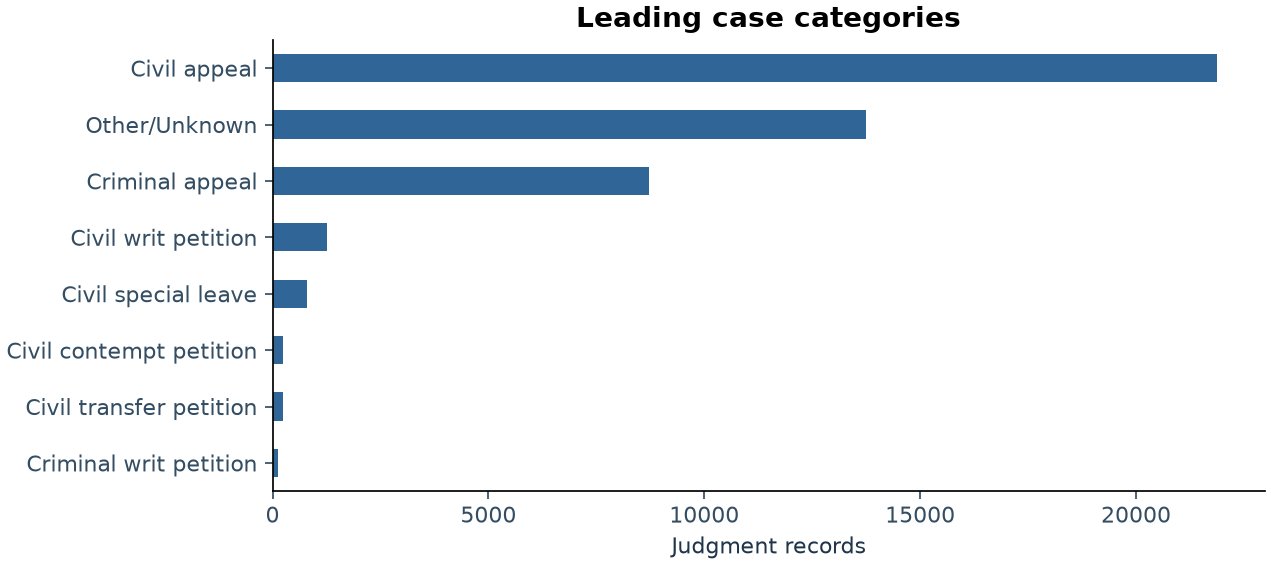

**Full CSV (47,400 records).** Civil appeal leads with 21,882 records (46.2%). 13,736 case numbers remain unclassified.

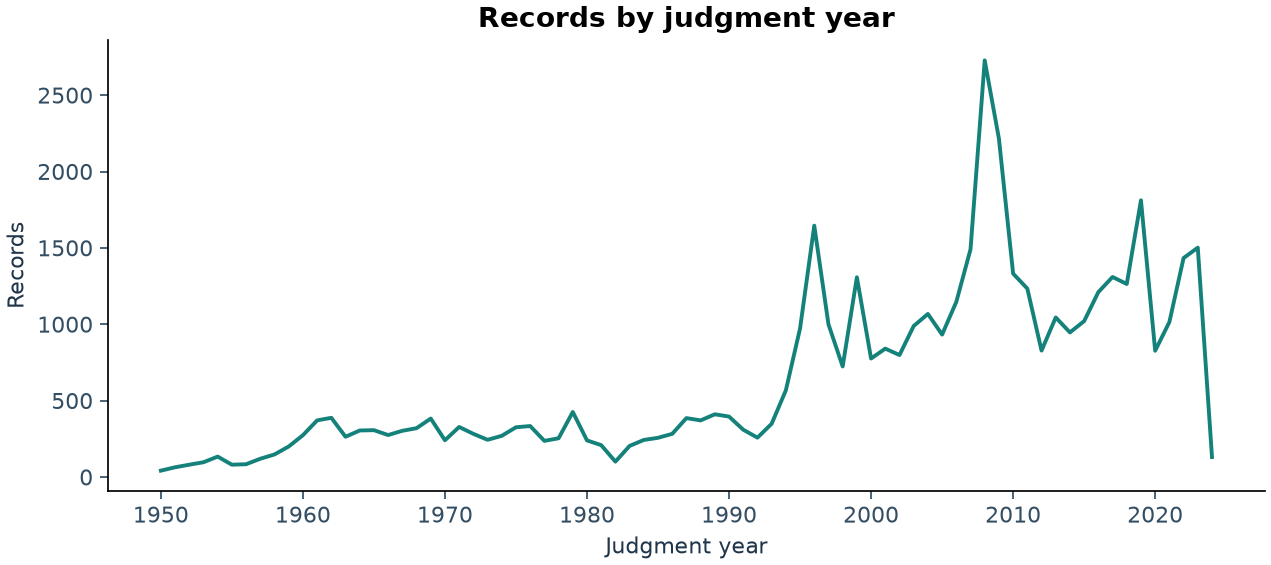

**Recorded chronology (47,397 rows after date review).** The largest annual count is 2,729 in 2008. The final recorded year, 2024, has 132 rows.

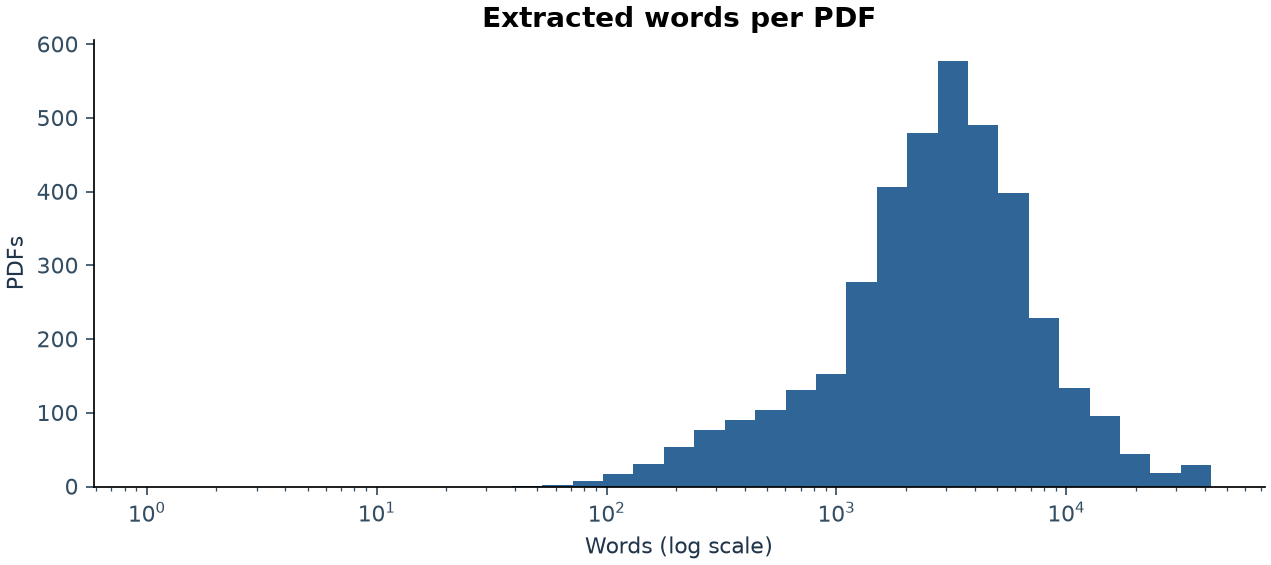

**Readable PDFs in the seed-42 sample (3,843 documents).** The median is 2,915 words and the 90th percentile is 8,412. 17 sampled PDFs reached the character cap.

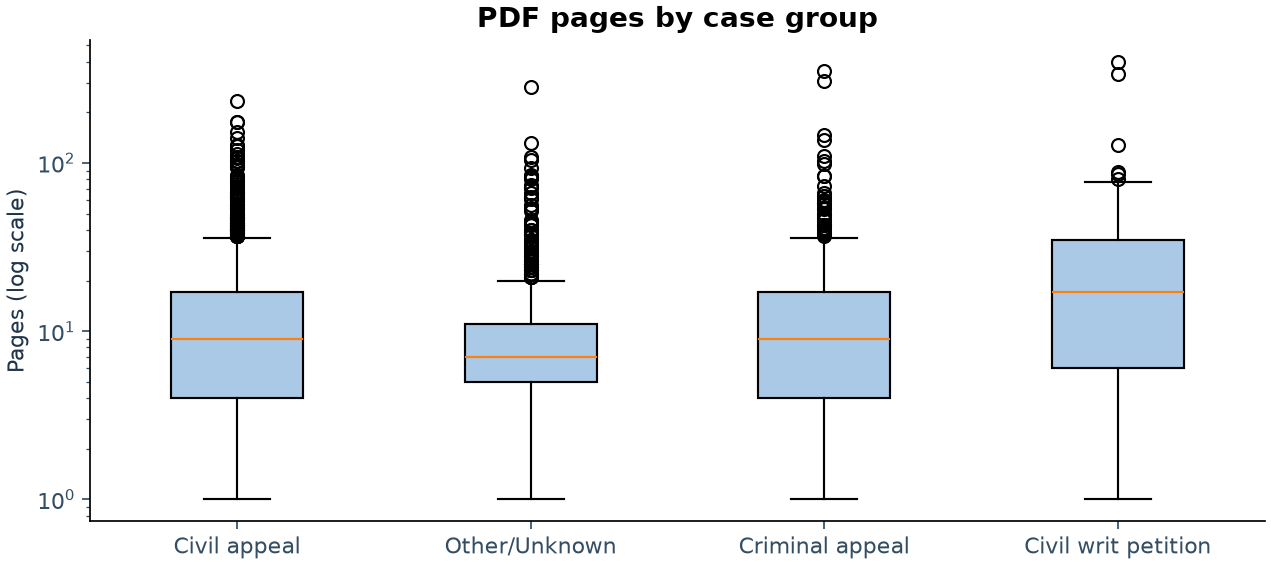

**Readable PDFs in the seed-42 sample (3,843 documents).** Median page counts for the displayed groups are Civil appeal 9 (n=1,760), Other/Unknown 7 (n=1,127), Criminal appeal 9 (n=723), Civil writ petition 17 (n=92).

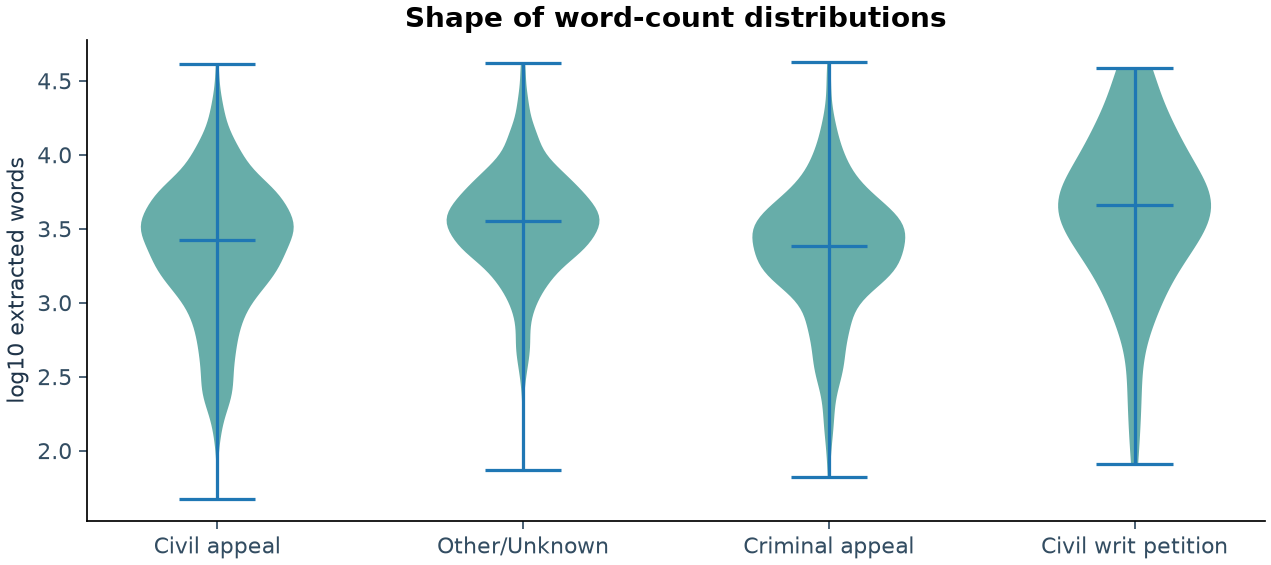

**Readable PDFs in the seed-42 sample (3,843 documents).** Civil writ petition has the widest middle half of log-lengths among the displayed groups (IQR 0.63 log10 units).

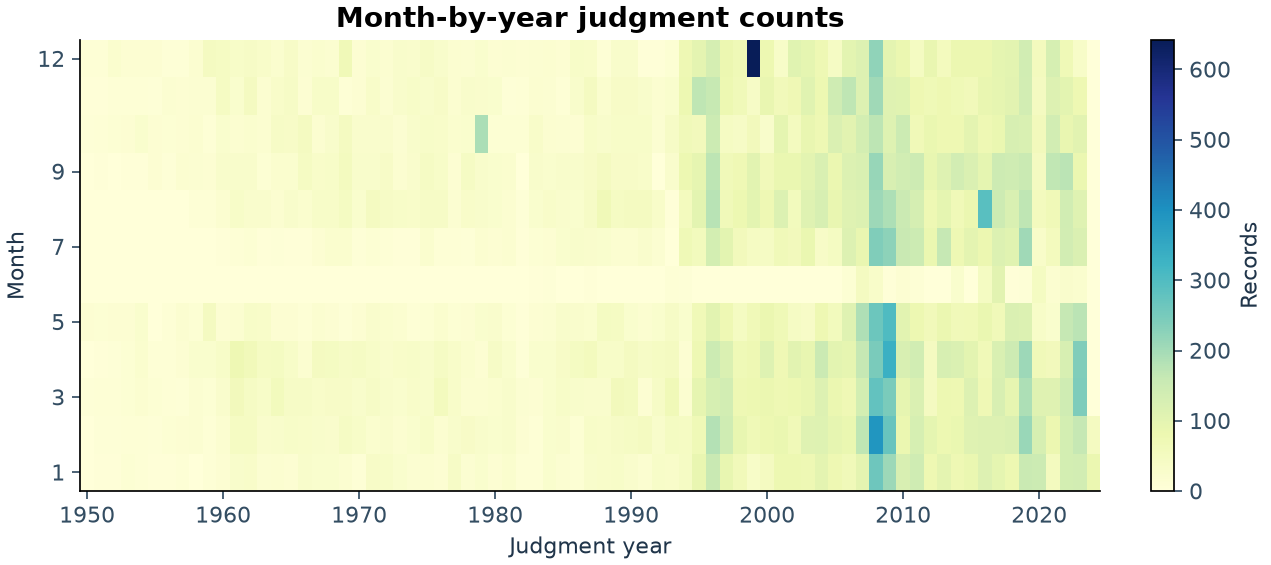

**Recorded chronology (47,397 rows after date review).** The highest individual month-year cell is 1999-12 with 642 records.

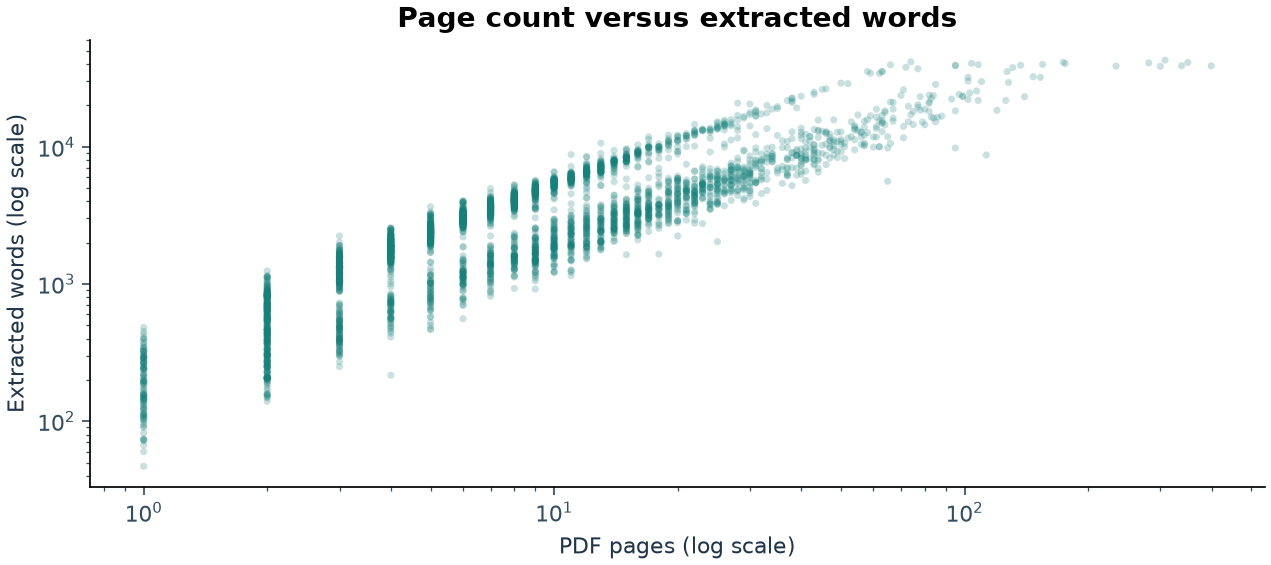

**Readable PDFs in the seed-42 sample (3,843 documents).** Page count and extracted word count have Spearman rank correlation 0.851.

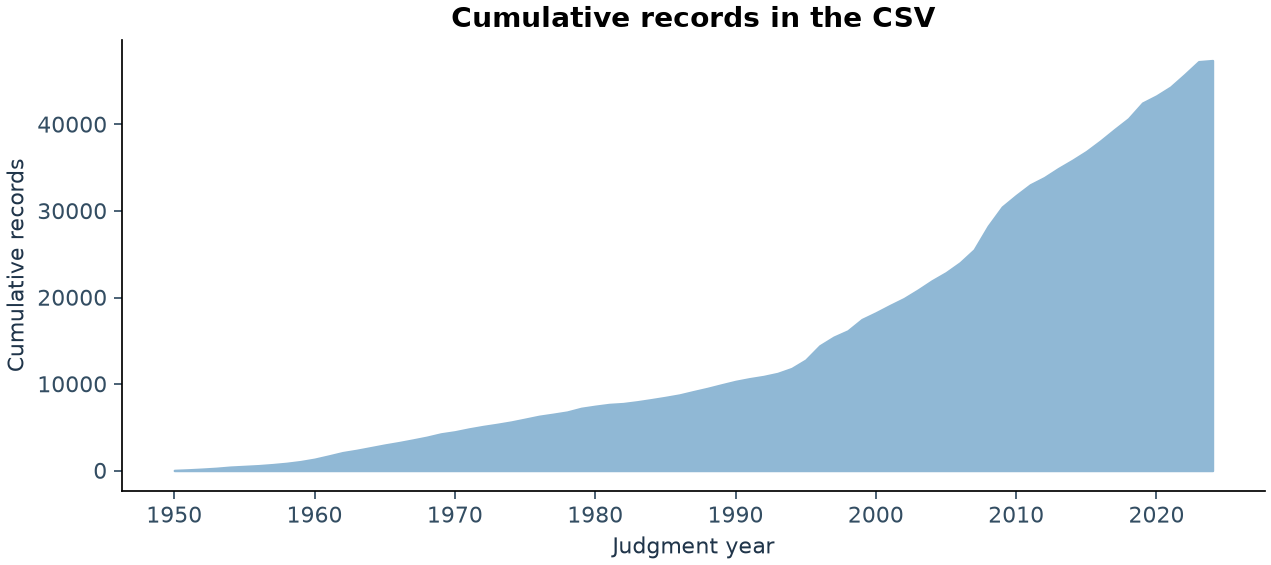

**Recorded chronology (47,397 rows after date review).** The cumulative total first reached half of the chronology records in 2006.

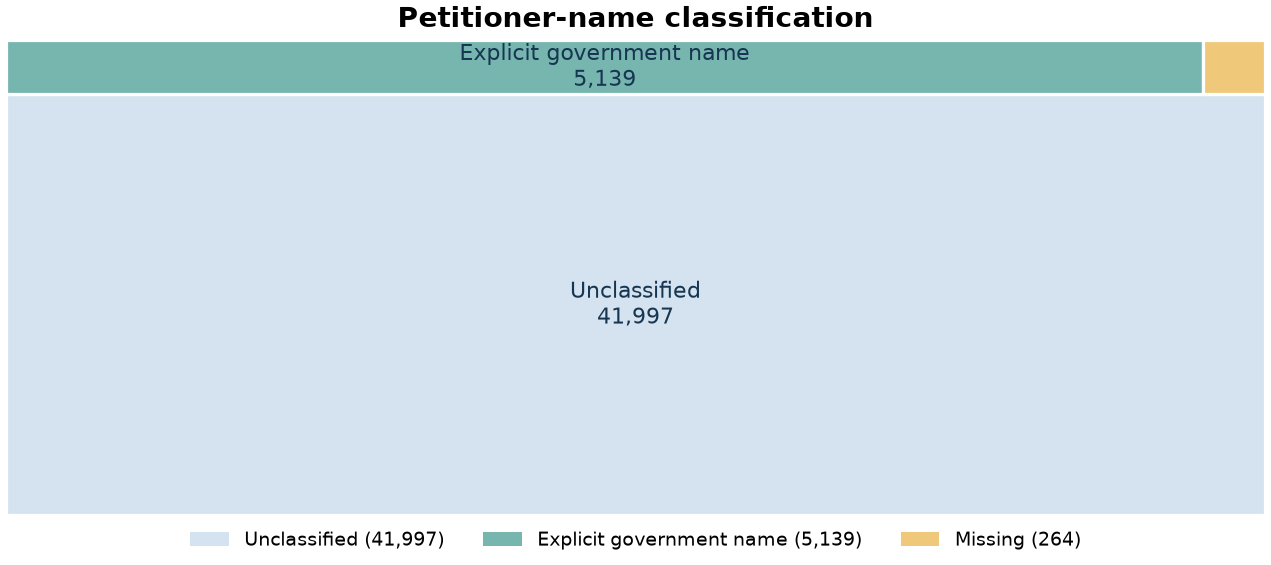

**Full CSV (47,400 records).** The strict name pattern flags 5,139 records (10.8%) and leaves 41,997 present names unclassified.

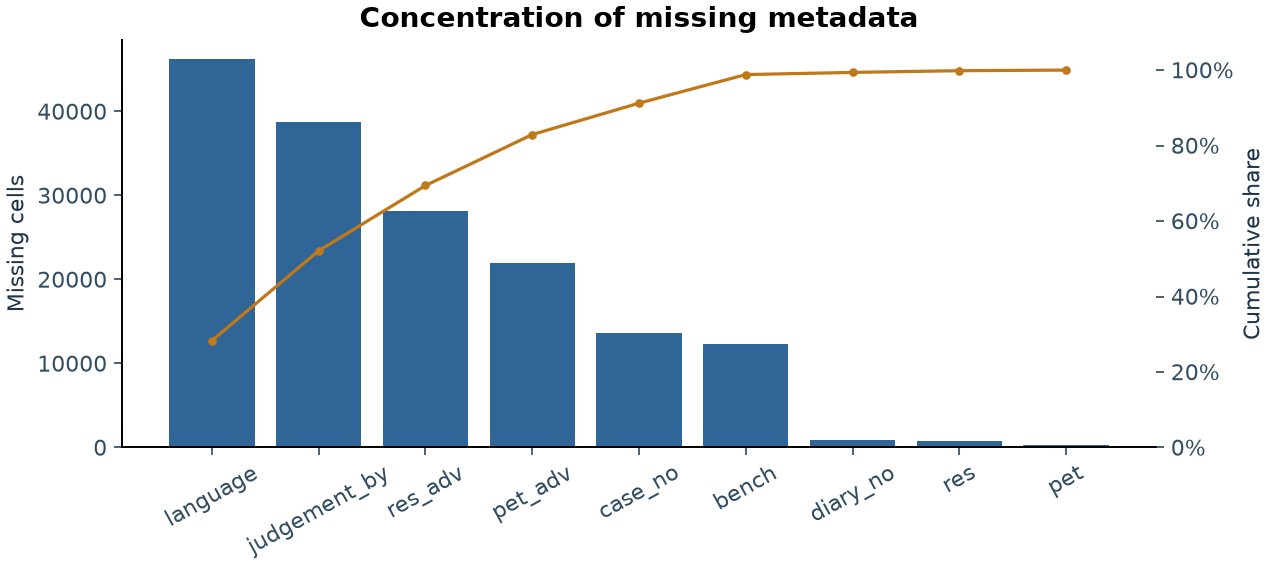

**Full CSV (47,400 records).** language and judgement_by account for 52.1% of the 163,069 missing cells across original fields.

In [3]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.ticker import PercentFormatter

plt.rcParams.update(
    {
        "figure.facecolor": "white",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.labelcolor": "#20354a",
        "xtick.color": "#334d62",
        "ytick.color": "#334d62",
        "axes.titlesize": 13,
        "axes.titleweight": "bold",
        "font.size": 10,
    }
)
BLUE, TEAL, GOLD = "#2f6597", "#15817b", "#bf781a"
artifacts = []


def chart():
    return plt.subplots(figsize=(8.2, 3.65), layout="constrained")


def save_chart(fig, filename, kind, title, basis, inference):
    path = FIGURES / filename
    fig.savefig(path, dpi=155, facecolor="white")
    plt.close(fig)
    observation = {
        "file": filename,
        "type": kind,
        "title": title,
        "basis": basis,
        "inference": inference,
    }
    artifacts.append(observation)
    display(Image(filename=str(path)))
    display(Markdown(f"**{basis}** {inference}"))


categories = meta.case_category.value_counts()
basis_csv = f"Full CSV ({len(meta):,} records)."
basis_text = f"Readable PDFs in the seed-{SEED} sample ({len(readable):,} documents)."
chrono = meta.loc[meta.date_review.eq("Recorded")].copy()
basis_time = f"Recorded chronology ({len(chrono):,} rows after date review)."
annual = chrono.groupby("judgment_year").size()
annual = annual.reindex(
    range(int(annual.index.min()), int(annual.index.max()) + 1), fill_value=0
)

fig, ax = chart()
categories.head(8).sort_values().plot.barh(ax=ax, color=BLUE)
ax.set(title="Leading case categories", xlabel="Judgment records", ylabel="")
save_chart(
    fig,
    "01_case_categories.png",
    "Bar",
    "Leading case categories",
    basis_csv,
    f"{categories.index[0]} leads with {categories.iloc[0]:,} records ({categories.iloc[0]/len(meta):.1%}). "
    f"{categories['Other/Unknown']:,} case numbers remain unclassified.",
)

fig, ax = chart()
ax.plot(annual.index, annual, color=TEAL, linewidth=1.8)
ax.set(title="Records by judgment year", xlabel="Judgment year", ylabel="Records")
save_chart(
    fig,
    "02_yearly_records.png",
    "Line",
    "Records by judgment year",
    basis_time,
    f"The largest annual count is {annual.max():,} in {annual.idxmax()}. "
    f"The final recorded year, {annual.index[-1]}, has {annual.iloc[-1]:,} rows.",
)

fig, ax = chart()
ax.hist(
    readable.word_count,
    bins=np.geomspace(1, max(2, readable.word_count.max()) + 1, 36),
    color=BLUE,
)
ax.set(
    xscale="log",
    title="Extracted words per PDF",
    xlabel="Words (log scale)",
    ylabel="PDFs",
)
save_chart(
    fig,
    "03_word_histogram.png",
    "Histogram",
    "Extracted words per PDF",
    basis_text,
    f"The median is {readable.word_count.median():,.0f} words and the 90th percentile is "
    f"{readable.word_count.quantile(.9):,.0f}. {pdf_summary['truncated']:,} sampled PDFs reached the character cap.",
)

group_names = list(readable.case_category.value_counts().head(4).index)
pdf_groups = [readable.loc[readable.case_category.eq(group)] for group in group_names]
fig, ax = chart()
ax.boxplot(
    [g.page_count for g in pdf_groups],
    tick_labels=group_names,
    patch_artist=True,
    boxprops={"facecolor": "#a9c9e7"},
)
ax.set(yscale="log", title="PDF pages by case group", ylabel="Pages (log scale)")
save_chart(
    fig,
    "04_pages_box.png",
    "Box plot",
    "PDF pages by case group",
    basis_text,
    "Median page counts for the displayed groups are "
    + ", ".join(
        f"{name} {group.page_count.median():g} (n={len(group):,})"
        for name, group in zip(group_names, pdf_groups)
    )
    + ".",
)

fig, ax = chart()
log_lengths = [np.log10(g.word_count.to_numpy()) for g in pdf_groups]
parts = ax.violinplot(log_lengths, showmedians=True)
for body in parts["bodies"]:
    body.set_facecolor(TEAL)
    body.set_alpha(0.65)
ax.set(
    xticks=np.arange(1, len(group_names) + 1),
    xticklabels=group_names,
    title="Shape of word-count distributions",
    ylabel="log10 extracted words",
)
iqrs = {
    name: float(np.quantile(values, 0.75) - np.quantile(values, 0.25))
    for name, values in zip(group_names, log_lengths)
}
widest = max(iqrs, key=iqrs.get)
save_chart(
    fig,
    "05_words_violin.png",
    "Violin",
    "Shape of word-count distributions",
    basis_text,
    f"{widest} has the widest middle half of log-lengths among the displayed groups "
    f"(IQR {iqrs[widest]:.2f} log10 units).",
)

months = pd.crosstab(chrono.judgment_year, chrono.judgment_month).reindex(
    index=annual.index, columns=range(1, 13), fill_value=0
)
fig, ax = chart()
heat = ax.imshow(
    months.T,
    origin="lower",
    aspect="auto",
    cmap="YlGnBu",
    extent=[annual.index.min() - 0.5, annual.index.max() + 0.5, 0.5, 12.5],
)
ax.set(
    title="Month-by-year judgment counts",
    xlabel="Judgment year",
    ylabel="Month",
    yticks=[1, 3, 5, 7, 9, 12],
)
fig.colorbar(heat, ax=ax, label="Records")
peak_year, peak_month = months.stack().idxmax()
save_chart(
    fig,
    "06_month_heatmap.png",
    "Heatmap",
    "Month-by-year judgment counts",
    basis_time,
    f"The highest individual month-year cell is {peak_year}-{peak_month:02d} with "
    f"{months.loc[peak_year, peak_month]:,} records.",
)

fig, ax = chart()
ax.scatter(
    readable.page_count,
    readable.word_count,
    s=11,
    alpha=0.23,
    color=TEAL,
    edgecolors="none",
)
ax.set(
    xscale="log",
    yscale="log",
    title="Page count versus extracted words",
    xlabel="PDF pages (log scale)",
    ylabel="Extracted words (log scale)",
)
rho = readable[["page_count", "word_count"]].corr(method="spearman").iloc[0, 1]
save_chart(
    fig,
    "07_pages_and_words.png",
    "Scatter",
    "Page count versus extracted words",
    basis_text,
    f"Page count and extracted word count have Spearman rank correlation {rho:.3f}.",
)

fig, ax = chart()
cumulative = annual.cumsum()
ax.fill_between(annual.index, cumulative, color="#90b8d5")
ax.set(
    title="Cumulative records in the CSV",
    xlabel="Judgment year",
    ylabel="Cumulative records",
)
midpoint_year = int(cumulative.index[cumulative.ge(len(chrono) / 2)][0])
save_chart(
    fig,
    "08_cumulative_records.png",
    "Area",
    "Cumulative records in the CSV",
    basis_time,
    f"The cumulative total first reached half of the chronology records in {midpoint_year}.",
)

fig, ax = chart()
pet_counts = meta.petitioner_category.value_counts()
palette = {
    "Unclassified": "#d4e3ef",
    "Explicit government name": "#77b5af",
    "Missing": "#efc879",
}


def treemap(items, x, y, width, height):
    # Split the weighted rectangles along their longest side.
    if len(items) == 1:
        label, count = items[0]
        ax.add_patch(
            Rectangle(
                (x, y), width, height, facecolor=palette[label], ec="white", lw=1.5
            )
        )
        if width * height > 0.035:
            ax.text(
                x + width / 2,
                y + height / 2,
                f"{label}\n{count:,}",
                ha="center",
                va="center",
                color="#173651",
            )
        return
    first, rest = items[:1], items[1:]
    fraction = first[0][1] / sum(n for _, n in items)
    if width > height:
        treemap(first, x, y, width * fraction, height)
        treemap(rest, x + width * fraction, y, width * (1 - fraction), height)
    else:
        treemap(first, x, y, width, height * fraction)
        treemap(rest, x, y + height * fraction, width, height * (1 - fraction))


items = list(pet_counts.items())
treemap(items, 0, 0, 1, 1)
ax.set(xlim=(0, 1), ylim=(0, 1), title="Petitioner-name classification")
ax.set_axis_off()
ax.legend(
    [Rectangle((0, 0), 1, 1, facecolor=palette[label]) for label, _ in items],
    [f"{label} ({count:,})" for label, count in items],
    loc="lower center",
    ncol=3,
    bbox_to_anchor=(0.5, -0.11),
    frameon=False,
    fontsize=9,
)
save_chart(
    fig,
    "09_petitioner_treemap.png",
    "Treemap",
    "Petitioner-name classification",
    basis_csv,
    f"The strict name pattern flags {pet_counts['Explicit government name']:,} records "
    f"({pet_counts['Explicit government name']/len(meta):.1%}) and leaves "
    f"{pet_counts['Unclassified']:,} present names unclassified.",
)

fig, ax = chart()
impact = missing.loc[missing.gt(0)].sort_values(ascending=False)
pos = np.arange(len(impact))
ax.bar(pos, impact, color=BLUE)
ax.set(
    title="Concentration of missing metadata",
    ylabel="Missing cells",
    xticks=pos,
    xticklabels=impact.index,
)
ax.tick_params(axis="x", labelrotation=29)
twin = ax.twinx()
twin.plot(pos, impact.cumsum() / impact.sum(), "o-", color=GOLD, markersize=3)
twin.set(ylim=(0, 1.08), ylabel="Cumulative share")
twin.yaxis.set_major_formatter(PercentFormatter(1))
save_chart(
    fig,
    "10_missingness_pareto.png",
    "Pareto",
    "Concentration of missing metadata",
    basis_csv,
    f"{impact.index[0]} and {impact.index[1]} account for {impact.iloc[:2].sum()/impact.sum():.1%} "
    f"of the {impact.sum():,} missing cells across original fields.",
)

assert len({item["type"] for item in artifacts}) == 10
write_json(OUT / "descriptive_figures.json", artifacts.copy())

## 4. Local FP-Growth

Encode each readable PDF as a binary basket of legal concepts. Mine frequent sets at 2% support, then retain rules with at least 50% confidence and 1.10 lift. Interpret the rules as textual co-occurrence.

C:\Users\theni\AppData\Local\Packages\openai.codex_2p2nqsd0c76g0\AC\#!sandbox.{bee92339-0c36-4b03-b23c-debe73f24128}\Temp\ipykernel_5708\1221868688.py:9: FutureWarning: Allowing arbitrary scalar fill_value in SparseDtype is deprecated. In a future version, the fill_value must be a valid value for the SparseDtype.subtype.
  one_hot = pd.DataFrame.sparse.from_spmatrix(


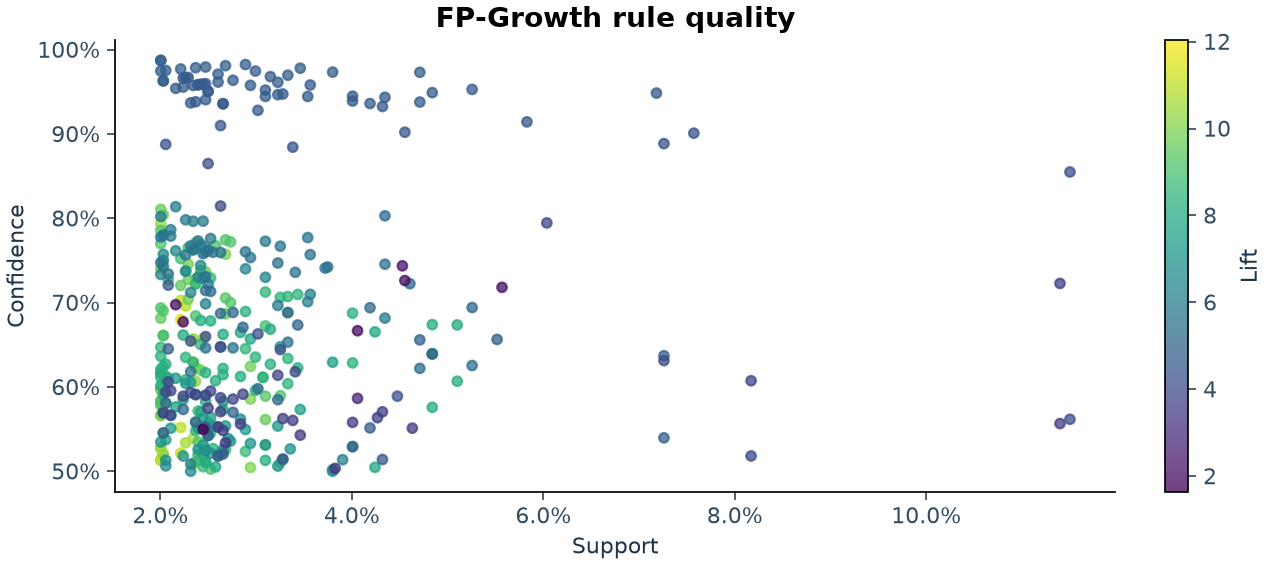

**417 rules across 3,843 baskets.** Confidence ranges from 50.0% to 98.7%. Lift ranges from 1.64 to 12.04.

,transactions,empty,observed_vocabulary,mean_items,max_items,min_support,min_confidence,min_lift,items,rules
0,3843,501,43,2.69477,19,0.02,0.5,1.1,192,417


,itemset,length,support_count,support
0,writ petition,1,1290,0.335675
1,penal code,1,787,0.204788
2,criminal procedure,1,606,0.157689
3,compensation,1,590,0.153526
4,first information report,1,517,0.134530
5,income tax,1,378,0.098361
6,tenant,1,337,0.087692
7,murder,1,323,0.084049
8,fundamental rights,1,298,0.077544
9,benefit of doubt,1,292,0.075982


,antecedent,consequent,support,confidence,lift
0,eyewitness | life imprisonment,medical evidence,0.020297,0.604651,12.039764
1,medical evidence | murder,eyewitness | penal code,0.022118,0.680000,11.666250
2,eyewitness | murder,medical evidence | penal code,0.022118,0.521472,11.071925
3,medical evidence | murder | penal code,eyewitness,0.022118,0.702479,11.018890
4,eyewitness | murder | penal code,medical evidence,0.022118,0.551948,10.990344
5,medical evidence | murder,eyewitness,0.022639,0.696000,10.917257
6,benefit of doubt | murder,first information report | life imprisonment |...,0.020036,0.513333,10.899116
7,benefit of doubt | murder,medical evidence | penal code,0.020036,0.513333,10.899116
8,benefit of doubt | murder | penal code,first information report | life imprisonment,0.020036,0.527397,10.896708
9,eyewitness | life imprisonment,first information report | murder,0.020036,0.596899,10.820206


Medical evidence → eyewitness: 61.1% of documents mentioning the antecedent also mention the consequent, against 6.4% in the entire readable sample (support 3.1%, lift 9.59).

Medical evidence → life imprisonment: 61.1% of documents mentioning the antecedent also mention the consequent, against 7.6% in the entire readable sample (support 3.1%, lift 8.07).

Life imprisonment → murder: 67.4% of documents mentioning the antecedent also mention the consequent, against 8.4% in the entire readable sample (support 5.1%, lift 8.01).

In [4]:
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import fpgrowth, association_rules

transactions = [tuple(sorted(set(items))) for items in readable.concepts]
n_tx = len(transactions)


def local_fp_growth(baskets):
    encoder = TransactionEncoder().fit(baskets)
    one_hot = pd.DataFrame.sparse.from_spmatrix(
        encoder.transform(baskets, sparse=True), columns=encoder.columns_
    )
    items = fpgrowth(one_hot, min_support=MIN_SUPPORT, use_colnames=True)
    return items


def counts_from_fp(items, n):
    return {
        item: round(fraction * n)
        for item, fraction in zip(items.itemsets, items.support)
    }


def label_set(itemset):
    return " | ".join(sorted(itemset))


def item_frame(counts, n):
    rows = [
        {
            "itemset": label_set(item),
            "length": len(item),
            "support_count": count,
            "support": count / n,
        }
        for item, count in counts.items()
    ]
    return pd.DataFrame(rows).sort_values(
        ["length", "support_count", "itemset"],
        ascending=[True, False, True],
        ignore_index=True,
    )


def tidy_rules(frame):
    return frame.assign(
        antecedent=frame.antecedents.map(label_set),
        consequent=frame.consequents.map(label_set),
    )[["antecedent", "consequent", "support", "confidence", "lift"]].sort_values(
        ["lift", "confidence", "support", "antecedent", "consequent"],
        ascending=[False, False, False, True, True],
        ignore_index=True,
    )


fp_items = local_fp_growth(transactions)
fp_counts = counts_from_fp(fp_items, n_tx)
fp_table = item_frame(fp_counts, n_tx)
fp_table.to_csv(OUT / "fp_itemsets.csv", index=False)
fp_lengths = fp_table.groupby("length").size().rename("itemsets")
fp_lengths.to_csv(OUT / "fp_itemsets_by_length.csv")
fp_rules_raw = association_rules(
    fp_items, metric="confidence", min_threshold=MIN_CONFIDENCE
)
fp_rules_raw = fp_rules_raw.loc[fp_rules_raw.lift.ge(MIN_LIFT)]
fp_rules = tidy_rules(fp_rules_raw)
fp_rules.to_csv(OUT / "fp_rules.csv", index=False)
for row in fp_rules_raw.itertuples():
    joint = fp_counts[row.antecedents | row.consequents]
    assert np.isclose(row.support, joint / n_tx)
    assert np.isclose(row.confidence, joint / fp_counts[row.antecedents])
    assert np.isclose(row.lift, row.confidence * n_tx / fp_counts[row.consequents])

concept_freq = Counter(item for tx in transactions for item in tx)
concept_table = pd.DataFrame(
    concept_freq.most_common(), columns=["concept", "documents"]
)
concept_table["support"] = concept_table.documents / n_tx
concept_table.to_csv(OUT / "concept_frequencies.csv", index=False)
readable[["record_id", "pdf_filename", "concepts"]].assign(
    concepts=readable.concepts.map(" | ".join)
).to_csv(OUT / "transactions.csv", index=False)
basket_lengths = pd.Series([len(tx) for tx in transactions], name="items")
basket_lengths.value_counts().sort_index().rename("baskets").to_csv(
    OUT / "transaction_sizes.csv"
)
strong_rules = []
# Favor simple, mutually distinct concept pairs in the narrative.
seen_pairs = set()
for row in fp_rules.itertuples(index=False):
    pair = frozenset((row.antecedent, row.consequent))
    if " | " in row.antecedent or " | " in row.consequent or pair in seen_pairs:
        continue
    seen_pairs.add(pair)
    strong_rules.append(
        f"{row.antecedent.capitalize()} → {row.consequent}: {row.confidence:.1%} of documents mentioning "
        f"the antecedent also mention the consequent, against {row.confidence/row.lift:.1%} "
        f"in the entire readable sample (support {row.support:.1%}, lift {row.lift:.2f})."
    )
    if len(strong_rules) == 3:
        break

fp_summary = {
    "transactions": n_tx,
    "empty": int(basket_lengths.eq(0).sum()),
    "observed_vocabulary": len(concept_freq),
    "mean_items": float(basket_lengths.mean()),
    "max_items": int(basket_lengths.max()),
    "min_support": MIN_SUPPORT,
    "min_confidence": MIN_CONFIDENCE,
    "min_lift": MIN_LIFT,
    "items": len(fp_table),
    "itemsets_by_length": {int(k): int(v) for k, v in fp_lengths.items()},
    "rules": len(fp_rules),
    "interpretations": strong_rules,
}
write_json(OUT / "fp_summary.json", fp_summary)
fig, ax = chart()
points = ax.scatter(
    fp_rules.support,
    fp_rules.confidence,
    c=fp_rules.lift,
    cmap="viridis",
    s=20,
    alpha=0.75,
)
ax.set(title="FP-Growth rule quality", xlabel="Support", ylabel="Confidence")
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.yaxis.set_major_formatter(PercentFormatter(1))
fig.colorbar(points, ax=ax, label="Lift")
save_chart(
    fig,
    "11_fp_rule_quality.png",
    "Rule-quality scatter",
    "FP-Growth rule quality",
    f"{len(fp_rules):,} rules across {n_tx:,} baskets.",
    f"Confidence ranges from {fp_rules.confidence.min():.1%} to {fp_rules.confidence.max():.1%}. "
    f"Lift ranges from {fp_rules.lift.min():.2f} to {fp_rules.lift.max():.2f}.",
)
write_json(OUT / "fp_figure.json", artifacts[-1])
display(
    pd.DataFrame([fp_summary]).drop(columns=["interpretations", "itemsets_by_length"])
)
display(fp_table.head(10))
display(fp_rules.head(10))
for interpretation in strong_rules:
    display(Markdown(interpretation))

## 5. A-Close and independent closure verification

Enumerate frequent minimal generators, intersect their supporting baskets, and recover frequent supports from the closed sets. Verify the implementation against exhaustive reference cases and compare the full workload with the 1,000-document prefix.

In [5]:
from math import ceil


def mine_generators(items, n, count_candidates, level_log=None):
    cutoff = ceil(n * MIN_SUPPORT)
    candidates = [(item,) for item in sorted(items)]
    counts = {frozenset(): n}
    while candidates:
        observed = count_candidates(candidates, cutoff)
        frequent = {
            terms: int(count) for terms, count in observed.items() if count >= cutoff
        }
        # Equal support with an immediate subset gives the same matching baskets.
        # Every superset inherits this redundancy, so discard the candidate before joining.
        level = {}
        for terms, count in frequent.items():
            itemset = frozenset(terms)
            if all(counts[itemset - {term}] > count for term in terms):
                level[terms] = count
                counts[itemset] = count
        if level_log is not None:
            level_log.append(
                {
                    "length": len(candidates[0]),
                    "candidates_counted": len(candidates),
                    "frequent_candidates": len(frequent),
                    "minimal_generators": len(level),
                }
            )
        if not level:
            break
        groups = defaultdict(list)
        for itemset in sorted(level):
            groups[itemset[:-1]].append(itemset[-1])
        candidates = [
            prefix + suffix
            for prefix, choices in groups.items()
            for suffix in combinations(choices, 2)
            if all(
                subset in level
                for subset in combinations(prefix + suffix, len(prefix) + 1)
            )
        ]
    return counts


def supports_from_closures(generator_counts, mapping):
    # Every frequent set is contained in its own closure. Its support is the
    # maximum support of its closed supersets. Expand for rule denominators and QA.
    closed = {closure: generator_counts[g] for g, closure in mapping.items() if closure}
    counts = {frozenset(): generator_counts[frozenset()]}
    for closure, count in sorted(closed.items(), key=lambda item: -item[1]):
        for length in range(1, len(closure) + 1):
            for subset in combinations(closure, length):
                counts.setdefault(frozenset(subset), count)
    return counts, mapping, closed


def local_a_close(baskets, level_log=None):
    # An integer bit mask records the transaction IDs containing each concept.
    universe = (1 << len(baskets)) - 1
    vertical = defaultdict(int)
    for index, basket in enumerate(baskets):
        bit = 1 << index
        for term in basket:
            vertical[term] |= bit

    def hits(candidate):
        relevant = universe
        for term in candidate:
            relevant &= vertical[term]
        return relevant

    def count_local(candidates, cutoff):
        return {candidate: hits(candidate).bit_count() for candidate in candidates}

    counts = mine_generators(vertical, len(baskets), count_local, level_log)
    mapping = {}
    for generator in counts:
        relevant = hits(generator)
        closure = frozenset(
            term for term, tids in vertical.items() if (tids & relevant) == relevant
        )
        mapping[generator] = closure
    return supports_from_closures(counts, mapping)


def exhaustive_closed(baskets):
    universe = sorted(set().union(*baskets))
    cutoff = ceil(len(baskets) * MIN_SUPPORT)
    reference = {}
    for size in range(1, len(universe) + 1):
        for terms in combinations(universe, size):
            subset = frozenset(terms)
            hits = [basket for basket in baskets if subset <= basket]
            if len(hits) >= cutoff and set.intersection(*hits) == subset:
                reference[subset] = len(hits)
    return reference


test_baskets = [
    {"always", "a", "b"},
    {"always", "a", "b", "c"},
    {"always", "c"},
    {"always", "d", "c"},
    {"always", "d"},
]
test_log = []
test_counts, test_generators, test_closed = local_a_close(test_baskets, test_log)
assert test_closed == exhaustive_closed(test_baskets)
assert test_generators[frozenset()] == frozenset({"always"})
assert frozenset({"a", "b"}) not in test_generators
assert test_counts[frozenset({"a", "b", "c"})] == 1
assert (
    test_log[1]["candidates_counted"] == 6
)  # 4 retained singletons, "always" was pruned.
assert all(row["length"] < 3 for row in test_log)  # Redundant pair blocks extension.
rng = np.random.default_rng(SEED)
for _ in range(12):
    check = [set(np.array(list("abcd"))[row]) for row in rng.random((20, 4)) < 0.45]
    assert local_a_close(check)[2] == exhaustive_closed(check)

generator_levels = []
a_counts, generators, closed_counts = local_a_close(transactions, generator_levels)
pd.DataFrame(generator_levels).to_csv(OUT / "aclose_levels.csv", index=False)
assert {item: count for item, count in a_counts.items() if item} == fp_counts
tx_sets = [set(tx) for tx in transactions]
for closure, count in closed_counts.items():
    hits = [basket for basket in tx_sets if closure <= basket]
    assert len(hits) == count and set.intersection(*hits) == closure
# In a downward-closed lattice, a same-support strict superset implies a same-support immediate extension.
nonclosed = {
    item - {term}
    for item, count in a_counts.items()
    for term in item
    if a_counts[item - {term}] == count
}
assert set(closed_counts) == set(fp_counts) - nonclosed

closed_table = item_frame(closed_counts, n_tx)
closed_table.to_csv(OUT / "aclose_closed_itemsets.csv", index=False)
pd.DataFrame(
    [
        {
            "generator": label_set(g),
            "closure": label_set(c),
            "support_count": a_counts[g],
        }
        for g, c in generators.items()
    ]
).to_csv(OUT / "aclose_generators.csv", index=False)
rule_rows = []
for closed, joint in closed_counts.items():
    for size in range(1, len(closed)):
        for left in map(frozenset, combinations(sorted(closed), size)):
            right = closed - left
            confidence = joint / a_counts[left]
            lift = confidence * n_tx / a_counts[right]
            if confidence >= MIN_CONFIDENCE and lift >= MIN_LIFT:
                rule_rows.append(
                    {
                        "antecedents": left,
                        "consequents": right,
                        "support": joint / n_tx,
                        "confidence": confidence,
                        "lift": lift,
                    }
                )
a_rules = tidy_rules(pd.DataFrame(rule_rows))
a_rules.to_csv(OUT / "aclose_rules.csv", index=False)
pairs_fp = {(r.antecedent, r.consequent) for r in fp_rules.itertuples()}
assert {(r.antecedent, r.consequent) for r in a_rules.itertuples()} <= pairs_fp
aclose_summary = {
    "frequent": len(fp_counts),
    "closed": len(closed_counts),
    "generators_including_empty": len(generators),
    "closed_union_rules": len(a_rules),
    "closed_by_length": {
        int(k): int(v) for k, v in closed_table.groupby("length").size().items()
    },
    "exhaustive_tests": 13,
    "full_data_counts_match_fp": True,
    "closure_verified": True,
}
write_json(OUT / "aclose_summary.json", aclose_summary)
display(pd.DataFrame([aclose_summary]).drop(columns="closed_by_length"))
display(closed_table.sort_values("support_count", ascending=False).head(8))
display(a_rules.head(8))

# Compare the benchmark prefix with the full sample using the same support threshold.
prefix = transactions[:1000]
prefix_counts, _, prefix_closed = local_a_close(prefix)
prefix_fp = counts_from_fp(local_fp_growth(prefix), len(prefix))
assert {item: count for item, count in prefix_counts.items() if item} == prefix_fp
assert prefix_closed == {
    item: count
    for item, count in prefix_fp.items()
    if not any(
        item < other and count == support for other, support in prefix_fp.items()
    )
}
comparison = []
for documents, frequent, closed in (
    (len(prefix), len(prefix_fp), len(prefix_closed)),
    (n_tx, len(fp_counts), len(closed_counts)),
):
    comparison.append(
        {
            "documents": documents,
            "frequent": frequent,
            "closed": closed,
            "nonclosed": frequent - closed,
            "reduction": (frequent - closed) / frequent,
        }
    )

smaller = frozenset({"benefit of doubt", "murder"})
hits = [set(basket) for basket in prefix if smaller.issubset(basket)]
larger = frozenset(set.intersection(*hits))
assert smaller < larger and prefix_counts[smaller] == prefix_closed[larger] == len(hits)
closure_example = {
    "itemset": label_set(smaller),
    "closure": label_set(larger),
    "documents": len(prefix),
    "support_count": len(hits),
    "support": len(hits) / len(prefix),
}
write_json(
    OUT / "aclose_workload_comparison.json",
    {"workloads": comparison, "example": closure_example},
)
display(pd.DataFrame(comparison).style.format({"reduction": "{:.2%}"}))
display(pd.DataFrame([closure_example]).style.format({"support": "{:.1%}"}))

,frequent,closed,generators_including_empty,closed_union_rules,exhaustive_tests,full_data_counts_match_fp,closure_verified
0,192,192,193,417,13,True,True


,itemset,length,support_count,support
0,writ petition,1,1290,0.335675
1,penal code,1,787,0.204788
2,criminal procedure,1,606,0.157689
3,compensation,1,590,0.153526
4,first information report,1,517,0.134530
39,first information report | penal code,2,442,0.115014
40,criminal procedure | penal code,2,438,0.113973
5,income tax,1,378,0.098361


,antecedent,consequent,support,confidence,lift
0,eyewitness | life imprisonment,medical evidence,0.020297,0.604651,12.039764
1,medical evidence | murder,eyewitness | penal code,0.022118,0.680000,11.666250
2,eyewitness | murder,medical evidence | penal code,0.022118,0.521472,11.071925
3,medical evidence | murder | penal code,eyewitness,0.022118,0.702479,11.018890
4,eyewitness | murder | penal code,medical evidence,0.022118,0.551948,10.990344
5,medical evidence | murder,eyewitness,0.022639,0.696000,10.917257
6,benefit of doubt | murder,first information report | life imprisonment |...,0.020036,0.513333,10.899116
7,benefit of doubt | murder,medical evidence | penal code,0.020036,0.513333,10.899116


,documents,frequent,closed,nonclosed,reduction
0,1000,193,172,21,10.88%
1,3843,192,192,0,0.00%


,itemset,closure,documents,support_count,support
0,benefit of doubt | murder,benefit of doubt | murder | penal code,1000,41,4.1%


## 6. K-Medoids on judgment text

Group readable text using TF-IDF, truncated SVD and cosine distance. Compare three starts for each k from 2 to 5 by medoid cost and mean silhouette. Use real judgment medoids and characteristic terms to interpret the exploratory groups.

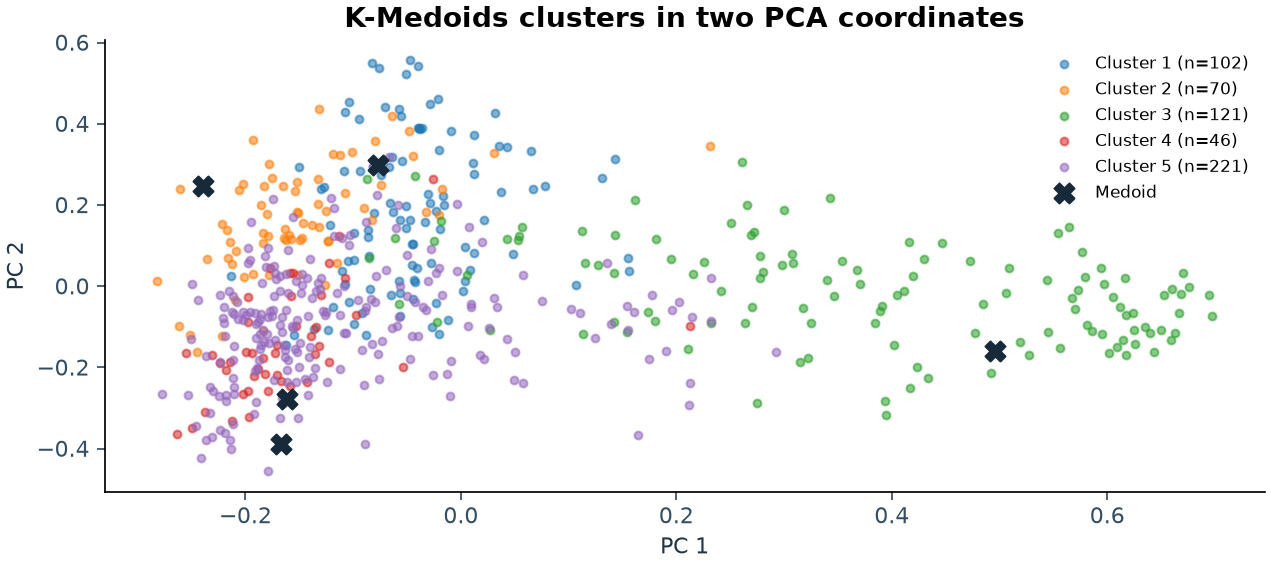

**560 documents. Distances use all 60 SVD coordinates.** k=5 has the highest silhouette (0.109). The plot retains 12.7% of variance in the normalized SVD features.

,k,silhouette,total_cosine_distance,starts
0,2,0.091122,303.152330,3
1,3,0.073744,287.362853,3
2,4,0.099900,275.509076,3
3,5,0.108922,264.110653,3


,cluster,size,medoid_record,medoid_diary_no,characteristic_terms
0,1,102,36689,8135-2004,"suit, decree, tenant, plaintiff, possession, d..."
1,2,70,24179,17457-2019,"posts, service, appointment, post, selection, ..."
2,3,121,39657,14799-1994,"accused, criminal, prosecution, deceased, offe..."
3,4,46,28409,60170-1966,"tax, assessee, income, income tax, tax act, as..."
4,5,221,20160,62772-1979,"constitution, government, notification, articl..."


In [6]:
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import cosine_distances
from sklearn.preprocessing import normalize
from threadpoolctl import threadpool_limits

candidates = readable.loc[
    readable.cluster_text.ne("") & readable.word_count.ge(100)
].copy()
candidates = candidates.loc[
    ~candidates.pdf_filename.str.contains("supremecourt_vernacular", regex=False)
].copy()
cluster_data = candidates.reset_index(drop=True)
stopwords = sorted(
    ENGLISH_STOP_WORDS
    | {
        "court",
        "high",
        "supreme",
        "judgment",
        "judgement",
        "justice",
        "learned",
        "said",
        "order",
        "hon",
        "ble",
        "versus",
        "case",
        "appellant",
        "respondent",
        "petitioner",
        "appeal",
        "page",
    }
)
vectorizer = TfidfVectorizer(
    stop_words=stopwords,
    min_df=3,
    max_df=0.85,
    max_features=8500,
    ngram_range=(1, 2),
    token_pattern=r"(?u)\b[a-zA-Z]{3,}\b",
    sublinear_tf=True,
    dtype=np.float32,
)
tfidf = vectorizer.fit_transform(cluster_data.cluster_text)
nonempty = np.asarray(tfidf.getnnz(axis=1)).ravel() > 0
cluster_data = cluster_data.loc[nonempty].reset_index(drop=True)
tfidf = tfidf[nonempty]
with threadpool_limits(limits=2):
    svd = TruncatedSVD(n_components=60, random_state=SEED)
    vectors = normalize(svd.fit_transform(tfidf))
    distance = cosine_distances(vectors).astype(np.float64)
distance = (distance + distance.T) / 2
np.fill_diagonal(distance, 0)


def pam(distance, initial):
    medoids = np.array(initial, dtype=int)
    current = distance[:, medoids].min(axis=1).sum()
    while True:
        active = distance[:, medoids]
        outside = np.setdiff1d(np.arange(len(distance)), medoids)
        best_cost = current
        best_swap = None
        for j in range(len(medoids)):
            retained = np.delete(active, j, axis=1).min(axis=1)
            costs = np.minimum(retained[:, None], distance[:, outside]).sum(axis=0)
            choice = int(costs.argmin())
            if costs[choice] < best_cost - 1e-9:
                best_cost = float(costs[choice])
                best_swap = j, outside[choice]
        if best_swap is None:
            labels = distance[:, medoids].argmin(axis=1)
            labels[medoids] = np.arange(len(medoids))
            return medoids, labels, float(current)
        j, candidate = best_swap
        medoids[j] = candidate
        current = best_cost


simple = np.abs(np.array([0, 1, 9, 10])[:, None] - np.array([0, 1, 9, 10])[None, :])
assert pam(simple, [0, 1])[2] == 2

rng = np.random.default_rng(SEED)
trials = []
solutions = {}
for k in range(2, 6):
    fits = [
        pam(distance, rng.choice(len(cluster_data), size=k, replace=False))
        for _ in range(3)
    ]
    medoids, labels, loss = min(fits, key=lambda result: result[2])
    score = float(silhouette_score(distance, labels, metric="precomputed"))
    trials.append(
        {
            "k": k,
            "silhouette": score,
            "total_cosine_distance": loss,
            "starts": len(fits),
        }
    )
    solutions[k] = medoids, labels, loss

trial_table = pd.DataFrame(trials)
trial_table.to_csv(OUT / "kmedoids_trials.csv", index=False)
selected_k = int(trial_table.loc[trial_table.silhouette.idxmax(), "k"])
medoids, labels, loss = solutions[selected_k]
assert len(set(medoids)) == selected_k and np.array_equal(
    labels[medoids], np.arange(selected_k)
)
assert np.isclose(distance[np.arange(len(labels)), medoids[labels]].sum(), loss)

feature_names = vectorizer.get_feature_names_out()
cluster_rows = []
for cluster, medoid in enumerate(medoids):
    member = labels == cluster
    cohort_mean = np.asarray(tfidf[member].mean(axis=0)).ravel()
    outside_mean = np.asarray(tfidf[~member].mean(axis=0)).ravel()
    term_order = np.argsort(cohort_mean - outside_mean)[::-1][:8]
    cluster_rows.append(
        {
            "cluster": cluster + 1,
            "size": int(member.sum()),
            "medoid_record": int(cluster_data.record_id.iloc[medoid]),
            "medoid_diary_no": str(cluster_data.diary_no.iloc[medoid]),
            "medoid_pdf": cluster_data.pdf_filename.iloc[medoid],
            "characteristic_terms": ", ".join(feature_names[term_order]),
        }
    )
cluster_table = pd.DataFrame(cluster_rows)
cluster_table.to_csv(OUT / "kmedoids_clusters.csv", index=False)
with threadpool_limits(limits=2):
    projector = PCA(n_components=2)
    projection = projector.fit_transform(vectors)
cluster_data[["record_id", "diary_no", "pdf_filename", "case_category"]].assign(
    cluster=labels + 1,
    is_medoid=np.isin(np.arange(len(labels)), medoids),
    pc1=projection[:, 0],
    pc2=projection[:, 1],
).to_csv(OUT / "kmedoids_assignments.csv", index=False)
best_score = float(trial_table.silhouette.max())
cluster_summary = {
    "sample": len(cluster_data),
    "selected_k": selected_k,
    "silhouette": best_score,
    "distance": "cosine",
    "tfidf_features": tfidf.shape[1],
    "svd_dimensions": vectors.shape[1],
    "svd_variance": float(svd.explained_variance_ratio_.sum()),
    "plot_variance": float(projector.explained_variance_ratio_.sum()),
    "min_words": 100,
}
write_json(OUT / "kmedoids_summary.json", cluster_summary)
fig, ax = chart()
for cluster in range(selected_k):
    member = labels == cluster
    ax.scatter(
        *projection[member].T,
        s=13,
        alpha=0.56,
        label=f"Cluster {cluster+1} (n={member.sum()})",
    )
ax.scatter(*projection[medoids].T, marker="X", s=85, color="#172a3a", label="Medoid")
ax.set(title="K-Medoids clusters in two PCA coordinates", xlabel="PC 1", ylabel="PC 2")
ax.legend(frameon=False, fontsize=8)
save_chart(
    fig,
    "12_kmedoids_projection.png",
    "Cluster projection",
    "K-Medoids clusters",
    f"{len(cluster_data):,} documents. Distances use all {vectors.shape[1]} SVD coordinates.",
    f"k={selected_k} has the highest silhouette ({best_score:.3f}). The plot retains "
    f"{cluster_summary['plot_variance']:.1%} of variance in the normalized SVD features.",
)
write_json(OUT / "kmedoids_figure.json", artifacts[-1])
display(trial_table)
display(cluster_table.drop(columns="medoid_pdf"))

## 7. Local versus PySpark benchmarks

Compare local and PySpark FP-Growth and A-Close on identical baskets. Include preparation, mining and collection in each timing and measure startup and warm-up separately. Check itemset supports and A-Close closures before interpreting the medians.

C:\Users\theni\AppData\Local\Packages\openai.codex_2p2nqsd0c76g0\AC\#!sandbox.{bee92339-0c36-4b03-b23c-debe73f24128}\Temp\ipykernel_5708\1221868688.py:9: FutureWarning: Allowing arbitrary scalar fill_value in SparseDtype is deprecated. In a future version, the fill_value must be a valid value for the SparseDtype.subtype.
  one_hot = pd.DataFrame.sparse.from_spmatrix(


C:\Users\theni\AppData\Local\Packages\openai.codex_2p2nqsd0c76g0\AC\#!sandbox.{bee92339-0c36-4b03-b23c-debe73f24128}\Temp\ipykernel_5708\1221868688.py:9: FutureWarning: Allowing arbitrary scalar fill_value in SparseDtype is deprecated. In a future version, the fill_value must be a valid value for the SparseDtype.subtype.
  one_hot = pd.DataFrame.sparse.from_spmatrix(


Saved verified benchmark: n=1,000, repetition 1/2


C:\Users\theni\AppData\Local\Packages\openai.codex_2p2nqsd0c76g0\AC\#!sandbox.{bee92339-0c36-4b03-b23c-debe73f24128}\Temp\ipykernel_5708\1221868688.py:9: FutureWarning: Allowing arbitrary scalar fill_value in SparseDtype is deprecated. In a future version, the fill_value must be a valid value for the SparseDtype.subtype.
  one_hot = pd.DataFrame.sparse.from_spmatrix(


Saved verified benchmark: n=1,000, repetition 2/2


C:\Users\theni\AppData\Local\Packages\openai.codex_2p2nqsd0c76g0\AC\#!sandbox.{bee92339-0c36-4b03-b23c-debe73f24128}\Temp\ipykernel_5708\1221868688.py:9: FutureWarning: Allowing arbitrary scalar fill_value in SparseDtype is deprecated. In a future version, the fill_value must be a valid value for the SparseDtype.subtype.
  one_hot = pd.DataFrame.sparse.from_spmatrix(


Saved verified benchmark: n=3,843, repetition 1/2


C:\Users\theni\AppData\Local\Packages\openai.codex_2p2nqsd0c76g0\AC\#!sandbox.{bee92339-0c36-4b03-b23c-debe73f24128}\Temp\ipykernel_5708\1221868688.py:9: FutureWarning: Allowing arbitrary scalar fill_value in SparseDtype is deprecated. In a future version, the fill_value must be a valid value for the SparseDtype.subtype.
  one_hot = pd.DataFrame.sparse.from_spmatrix(


Saved verified benchmark: n=3,843, repetition 2/2


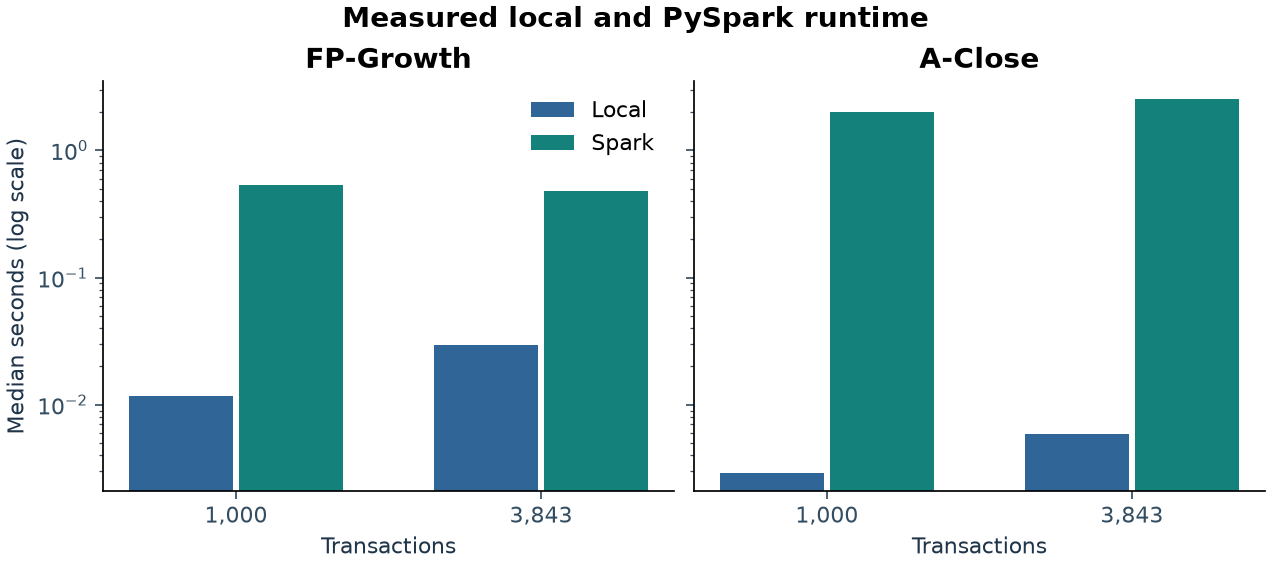

**2 measured runs per algorithm and workload after startup.** Full-sample local/Spark runtime ratios are FP-Growth 0.0619×, A-Close 0.00233×. Values below 1 indicate slower Spark execution.

,Spark,Startup (s),Warm-up (s)
0,4.0.1,15.79495,4.4627


,algorithm,documents,local_seconds,spark_seconds,frequent,closed,equal,speedup
0,FP-Growth,1000,0.0118,0.5357,193,—,True,0.0220
1,A-Close,1000,0.0029,2.0108,193,172,True,0.0015
2,FP-Growth,3843,0.0297,0.4798,192,—,True,0.0619
3,A-Close,3843,0.0058,2.5108,192,192,True,0.0023


In [7]:
import tempfile
from pyspark.sql import SparkSession, functions as F
from pyspark.ml.fpm import FPGrowth

os.environ.setdefault("SPARK_LOCAL_IP", "127.0.0.1")
os.environ.setdefault("PYSPARK_PYTHON", sys.executable)
os.environ.setdefault("PYSPARK_DRIVER_PYTHON", sys.executable)
if os.name == "nt":
    # Spark's Windows launcher cannot use Codex's temp path with CMD metacharacters.
    spark_temp = OUT / "spark_temp"
    spark_temp.mkdir(exist_ok=True)
    os.environ["TEMP"] = os.environ["TMP"] = str(spark_temp)
    tempfile.tempdir = str(spark_temp)
    os.environ.setdefault("SPARK_LOCAL_DIRS", str(spark_temp))


def spark_baskets(spark, baskets, name):
    # JVM-only parsing avoids Python worker launch on Windows.
    payload = F.lit(json.dumps(baskets, separators=(",", ":")))
    return spark.range(1).select(
        F.explode(F.from_json(payload, "array<array<string>>")).alias(name)
    )


def spark_fp(frame):
    rows = (
        FPGrowth(
            itemsCol="items",
            minSupport=MIN_SUPPORT,
            minConfidence=MIN_CONFIDENCE,
            numPartitions=2,
        )
        .fit(frame)
        .freqItemsets.collect()
    )
    return {frozenset(row.items): int(row.freq) for row in rows}


def spark_a_close(spark, frame, n):
    # Each match row is one candidate and a basket containing all its terms.
    def matching_baskets(candidates):
        candidate_frame = spark_baskets(spark, candidates, "candidate")
        return frame.crossJoin(F.broadcast(candidate_frame)).where(
            F.size(F.array_except(F.col("candidate"), F.col("items"))) == 0
        )

    def count_spark(candidates, cutoff):
        result = (
            matching_baskets(candidates)
            .groupBy("candidate")
            .count()
            .where(F.col("count") >= cutoff)
            .collect()
        )
        return {tuple(row.candidate): int(row["count"]) for row in result}

    vocabulary = [
        row.term
        for row in frame.select(F.explode("items").alias("term")).distinct().collect()
    ]
    counts = mine_generators(vocabulary, n, count_spark)
    # A term belongs to the closure iff every basket supporting the generator
    # also contains the term. SQL counts those co-occurrences across partitions.
    occurrences = (
        matching_baskets([sorted(g) for g in counts])
        .select("candidate", F.explode("items").alias("term"))
        .groupBy("candidate", "term")
        .count()
        .collect()
    )
    common = {generator: set() for generator in counts}
    for row in occurrences:
        generator = frozenset(row.candidate)
        if row["count"] == counts[generator]:
            common[generator].add(row.term)
    return supports_from_closures(
        counts, {g: frozenset(terms) for g, terms in common.items()}
    )


def measure_spark(spark, baskets, algorithm):
    start = time.perf_counter()
    frame = spark_baskets(spark, baskets, "items").repartition(2).cache()
    try:
        assert frame.count() == len(baskets)
        prepared = time.perf_counter()
        result = (
            spark_fp(frame)
            if algorithm == "FP-Growth"
            else spark_a_close(spark, frame, len(baskets))
        )
        elapsed = time.perf_counter() - start
        return result, elapsed, prepared - start
    finally:
        frame.unpersist(blocking=True)


spark_setup_start = time.perf_counter()
spark = (
    SparkSession.builder.master("local[2]")
    .appName("ASBD-judgment-analysis")
    .config("spark.ui.enabled", "false")
    .config("spark.driver.bindAddress", "127.0.0.1")
    .config("spark.driver.memory", "768m")
    .config("spark.sql.shuffle.partitions", "2")
    .config("spark.sql.adaptive.enabled", "false")
    .config("spark.sql.crossJoin.enabled", "true")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")
spark_version = spark.version
assert spark.range(4).count() == 4
startup_seconds = time.perf_counter() - spark_setup_start
write_json(
    OUT / "spark_startup.json",
    {"version": spark_version, "startup_seconds": startup_seconds},
)
bench_rows = []
prep_rows = []
workloads = sorted({min(1000, n_tx), n_tx})
repetitions = 2

try:
    # Warm one FPGrowth and one candidate-count path before taking measurements.
    warm_baskets = [("x",), ("x", "y"), ("y",), ()]
    assert measure_spark(spark, warm_baskets, "FP-Growth")[0] == counts_from_fp(
        local_fp_growth(warm_baskets), 4
    )
    assert measure_spark(spark, warm_baskets, "A-Close")[0] == local_a_close(
        warm_baskets
    )
    warmup_seconds = time.perf_counter() - spark_setup_start - startup_seconds
    for n in workloads:
        baskets = transactions[:n]
        for attempt in range(1, repetitions + 1):
            t = time.perf_counter()
            local_fp = counts_from_fp(local_fp_growth(baskets), n)
            local_seconds = time.perf_counter() - t
            distributed_fp, spark_seconds, prep = measure_spark(
                spark, baskets, "FP-Growth"
            )
            assert distributed_fp == local_fp
            bench_rows.append(
                {
                    "algorithm": "FP-Growth",
                    "documents": n,
                    "repeat": attempt,
                    "local_seconds": local_seconds,
                    "spark_seconds": spark_seconds,
                    "spark_prepare_seconds": prep,
                    "frequent": len(local_fp),
                    "closed": None,
                    "equal": True,
                }
            )
            pd.DataFrame(bench_rows).to_csv(
                OUT / "spark_benchmark_runs.csv", index=False
            )

            t = time.perf_counter()
            local_closed = local_a_close(baskets)
            local_seconds = time.perf_counter() - t
            distributed_closed, spark_seconds, prep = measure_spark(
                spark, baskets, "A-Close"
            )
            assert distributed_closed == local_closed
            assert {
                s: c for s, c in distributed_closed[0].items() if s
            } == distributed_fp
            bench_rows.append(
                {
                    "algorithm": "A-Close",
                    "documents": n,
                    "repeat": attempt,
                    "local_seconds": local_seconds,
                    "spark_seconds": spark_seconds,
                    "spark_prepare_seconds": prep,
                    "frequent": len(local_fp),
                    "closed": len(local_closed[2]),
                    "equal": True,
                }
            )
            pd.DataFrame(bench_rows).to_csv(
                OUT / "spark_benchmark_runs.csv", index=False
            )
            print(
                f"Saved verified benchmark: n={n:,}, repetition {attempt}/{repetitions}"
            )
        prep_rows.append(
            {
                "documents": n,
                "spark_cache_seconds": float(
                    np.median(
                        [
                            row["spark_prepare_seconds"]
                            for row in bench_rows
                            if row["documents"] == n
                        ]
                    )
                ),
            }
        )
finally:
    spark.stop()

benchmark = pd.DataFrame(bench_rows)
timing = (
    benchmark.groupby(["algorithm", "documents"], sort=False)
    .agg(
        local_seconds=("local_seconds", "median"),
        spark_seconds=("spark_seconds", "median"),
        frequent=("frequent", "first"),
        closed=("closed", "first"),
        equal=("equal", "all"),
    )
    .reset_index()
)
timing["speedup"] = timing.local_seconds / timing.spark_seconds
timing.to_csv(OUT / "spark_benchmark_summary.csv", index=False)
spark_summary = {
    "version": spark_version,
    "master": "local[2]",
    "startup_seconds": startup_seconds,
    "warmup_seconds": warmup_seconds,
    "preparation": prep_rows,
    "repetitions": repetitions,
    "workloads": workloads,
    "all_supports_equal": bool(timing.equal.all()),
}
write_json(OUT / "spark_summary.json", spark_summary)

fig, axes = plt.subplots(1, 2, figsize=(8.2, 3.65), layout="constrained", sharey=True)
for ax, (algorithm, group) in zip(axes, timing.groupby("algorithm", sort=False)):
    positions = np.arange(len(group))
    ax.bar(positions - 0.18, group.local_seconds, width=0.34, color=BLUE, label="Local")
    ax.bar(positions + 0.18, group.spark_seconds, width=0.34, color=TEAL, label="Spark")
    ax.set(
        title=algorithm,
        yscale="log",
        xlabel="Transactions",
        xticks=positions,
        xticklabels=[f"{n:,}" for n in group.documents],
    )
axes[0].set_ylabel("Median seconds (log scale)")
axes[0].legend(frameon=False)
fig.suptitle("Measured local and PySpark runtime", fontsize=13, fontweight="bold")
full = timing[timing.documents.eq(n_tx)]
runtime_inference = (
    "Full-sample local/Spark runtime ratios are "
    + ", ".join(f"{row.algorithm} {row.speedup:.3g}×" for row in full.itertuples())
    + ". Values below 1 indicate slower Spark execution."
)
save_chart(
    fig,
    "13_runtime_comparison.png",
    "Runtime bars",
    "Local and Spark benchmark",
    f"{repetitions} measured runs per algorithm and workload after startup.",
    runtime_inference,
)
write_json(OUT / "spark_figure.json", artifacts[-1])
display(
    pd.DataFrame(
        [
            {
                "Spark": spark_version,
                "Startup (s)": startup_seconds,
                "Warm-up (s)": warmup_seconds,
            }
        ]
    )
)
display(
    timing.style.format(
        {
            "local_seconds": "{:.4f}",
            "spark_seconds": "{:.4f}",
            "speedup": "{:.4f}",
            "closed": "{:.0f}",
        },
        na_rep="—",
    )
)

## 8. Report from executed results and notebook checks

Compare case-category shares in the full metadata and the readable mining sample using record IDs. Export the category comparison and build a reproducible analysis summary under `outputs/`. The detailed submission PDF is maintained separately.

In [8]:
from xml.sax.saxutils import escape
from reportlab.lib import colors
from reportlab.lib.enums import TA_CENTER
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import ParagraphStyle
from reportlab.platypus import (
    Image as ReportImage,
    PageBreak,
    Paragraph,
    SimpleDocTemplate,
    Spacer,
    Table,
    TableStyle,
)

# Compare the full record mix with the exact readable workload used for mining.
sample_metadata = pd.read_csv(
    OUT / "metadata_clean.csv", usecols=["record_id", "case_category"]
)
sample_features = pd.read_csv(
    OUT / "pdf_sample_features.csv", usecols=["record_id", "status"]
)
readable_categories = sample_features.loc[
    sample_features.status.eq("ok"), ["record_id"]
].merge(sample_metadata, on="record_id", how="left", validate="one_to_one")
assert (
    sample_metadata.case_category.notna().all()
    and readable_categories.case_category.notna().all()
)
assert len(sample_metadata) == metadata["rows"] and len(readable_categories) == n_tx

category_mix = pd.DataFrame(
    {"full_count": sample_metadata.case_category.value_counts()}
)
category_mix.index.name = "case_category"
category_mix[
    "readable_count"
] = readable_categories.case_category.value_counts().reindex(
    category_mix.index, fill_value=0
)
category_mix["full_pct"] = 100 * category_mix["full_count"] / len(sample_metadata)
category_mix["readable_pct"] = (
    100 * category_mix["readable_count"] / len(readable_categories)
)
category_mix["difference_pp"] = category_mix["readable_pct"] - category_mix["full_pct"]
category_mix.to_csv(OUT / "sample_representativeness.csv", float_format="%.8f")
main_groups = ", ".join(
    f"{category} {row.full_pct:.2f}% to {row.readable_pct:.2f}% ({row.difference_pp:+.2f} pp)"
    for category, row in category_mix.head(3).iterrows()
)
largest_gap = category_mix["difference_pp"].abs().max()
print(
    "Case-category comparison (difference = readable percentage minus full percentage)"
)
print(category_mix.round(4).to_string())

PDF_PATH = OUT / "ASBD_EndSem_Analysis_Summary.pdf"
ink, muted, accent = [colors.HexColor(c) for c in ("#172f46", "#4b6174", "#13736f")]
paper, line = colors.HexColor("#eef5f8"), colors.HexColor("#cbd9e2")
styles = {
    "tag": ParagraphStyle(
        "tag",
        fontName="Helvetica-Bold",
        fontSize=9,
        leading=12,
        textColor=accent,
        spaceAfter=7,
    ),
    "title": ParagraphStyle(
        "title",
        fontName="Helvetica-Bold",
        fontSize=30,
        leading=34,
        textColor=ink,
        spaceAfter=12,
    ),
    "section": ParagraphStyle(
        "section",
        fontName="Helvetica-Bold",
        fontSize=22,
        leading=26,
        textColor=ink,
        spaceAfter=8,
    ),
    "sub": ParagraphStyle(
        "sub",
        fontName="Helvetica-Bold",
        fontSize=12,
        leading=15,
        textColor=ink,
        spaceBefore=10,
        spaceAfter=4,
    ),
    "body": ParagraphStyle(
        "body",
        fontName="Helvetica",
        fontSize=9.5,
        leading=13.2,
        textColor=ink,
        spaceAfter=7,
    ),
    "caption": ParagraphStyle(
        "caption",
        fontName="Helvetica",
        fontSize=8.5,
        leading=11.5,
        textColor=muted,
        spaceAfter=8,
    ),
    "cell": ParagraphStyle(
        "cell", fontName="Helvetica", fontSize=8.3, leading=10.6, textColor=ink
    ),
    "cell_head": ParagraphStyle(
        "cell_head",
        fontName="Helvetica-Bold",
        fontSize=8.2,
        leading=10.4,
        textColor=colors.white,
    ),
    "metric": ParagraphStyle(
        "metric",
        fontName="Helvetica-Bold",
        fontSize=18,
        leading=22,
        textColor=ink,
        alignment=TA_CENTER,
    ),
    "metric_label": ParagraphStyle(
        "metric_label",
        fontName="Helvetica",
        fontSize=8.5,
        leading=10.5,
        textColor=muted,
        alignment=TA_CENTER,
    ),
}
story = []


def rich(value, style):
    safe = (
        str(value)
        .replace("→", " to ")
        .replace("—", "-")
        .replace("–", "-")
        .replace("×", "x")
    )
    return Paragraph(escape(safe), styles[style])


def add(value, style="body"):
    story.append(rich(value, style))


def section(tag, title):
    story.append(PageBreak())
    add(tag, "tag")
    add(title, "section")


def table(headers, rows, widths):
    contents = [[rich(x, "cell_head") for x in headers]]
    contents += [[rich(x, "cell") for x in row] for row in rows]
    result = Table(contents, colWidths=widths, repeatRows=1, hAlign="LEFT")
    result.setStyle(
        TableStyle(
            [
                ("BACKGROUND", (0, 0), (-1, 0), ink),
                ("ROWBACKGROUNDS", (0, 1), (-1, -1), [colors.white, paper]),
                ("LINEBELOW", (0, -1), (-1, -1), 0.45, line),
                ("VALIGN", (0, 0), (-1, -1), "TOP"),
                ("LEFTPADDING", (0, 0), (-1, -1), 7),
                ("RIGHTPADDING", (0, 0), (-1, -1), 7),
                ("TOPPADDING", (0, 0), (-1, -1), 5),
                ("BOTTOMPADDING", (0, 0), (-1, -1), 5),
            ]
        )
    )
    story.extend([result, Spacer(1, 8)])


def figure(item, width=487):
    number = item["file"].split("_", 1)[0]
    image = ReportImage(
        str(FIGURES / item["file"]), width=width, height=width * 3.65 / 8.2
    )
    image.hAlign = "CENTER"
    story.append(image)
    add(
        f"Figure {number}. {item['type']}. " f"{item['basis']} {item['inference']}",
        "caption",
    )


add(
    "Indian Institute of Information Technology Design & Manufacturing Kancheepuram, Chennai-127",
    "tag",
)
add("25CS5004 / CS 5010  |  Analytics & Systems of Big Data Practice", "sub")
add("End-semester examination  |  November 2025  |  Maximum marks 50", "caption")
add("Indian Supreme Court judgments", "title")
add("Metadata coverage, legal-concept co-occurrence and text clustering")
metrics = [
    [
        f"{metadata['rows']:,}",
        f"{metadata['matched_rows']/metadata['rows']:.2%}",
        f"{pdf_summary['readable']:,}",
        f"{cluster_summary['sample']:,}",
    ],
    [
        "Metadata records",
        "Exact PDF match",
        "Readable sampled PDFs",
        "Clustered documents",
    ],
]
cards = Table(
    [
        [rich(x, "metric") for x in metrics[0]],
        [rich(x, "metric_label") for x in metrics[1]],
    ],
    colWidths=[124.5] * 4,
    hAlign="LEFT",
)
cards.setStyle(
    TableStyle(
        [
            ("BACKGROUND", (0, 0), (-1, -1), paper),
            ("TOPPADDING", (0, 0), (-1, 0), 9),
            ("BOTTOMPADDING", (0, 1), (-1, 1), 9),
        ]
    )
)
story.extend([cards, Spacer(1, 8)])
add("Scope and data preparation", "sub")
add(
    f"The source CSV contains {metadata['columns']} original fields and the archive contains "
    f"{metadata['pdf_files']:,} PDF files. The analysis uses dates and case numbers for chronology and categories, "
    "party and advocate fields for coverage, judge and bench fields for completeness, and matching PDFs for text. "
    "Whitespace and missing markers were standardized. J and judgment map to one Judgment category."
)
d = metadata["repeats"]["diary_no"]
l = metadata["repeats"]["temp_link"]
add(
    f"The CSV contains {metadata['exact_duplicate_rows']:,} completely duplicate rows. "
    f"{d['groups']:,} diary IDs repeat ({d['extra_rows']:,} extra occurrences), and {l['groups']:,} links repeat "
    f"({l['extra_rows']:,} extra occurrences). {d['groups_with_different_files']:,} repeated diary groups and "
    f"{l['groups_with_different_files']:,} repeated link groups point to different constructed filenames. "
    "All rows remain in the metadata analysis. The PDF sampling frame uses unique filenames."
)
add(
    f"The exact filename rule leaves {metadata['unmatched_rows']} unmatched rows. "
    f"{metadata['same_link_candidates']} have a same-link match under a different diary number and "
    f"{metadata['near_name_candidates']} have a similar filename under the same diary number. "
    "The similar filenames were logged for review and left unmatched because some point to a different language or document."
)
add("Derived fields and disputed dates", "sub")
add(
    f"Dates use day-first parsing. Case groups use leading case-number patterns. Bench size is populated in "
    f"{metadata['reliable_bench_sizes']:,} records with explicit judge titles and compatible comma separators. "
    "Petitioner groups flag explicit government names and preserve unclassified and missing values. "
    "PDF presence is a filename check. Page and word counts are derived for the sampled documents."
)
table(
    ["Record", "CSV date", "Case year", "PDF date header"],
    [
        (
            f"{row.record_id:,}",
            row.judgment_dates,
            row.case_no.rsplit(" ", 1)[-1],
            row.pdf_date_evidence.split(" | ", 1)[0].removeprefix("DATE OF JUDGMENT: "),
        )
        for row in review_dates.itertuples()
    ],
    [68, 86, 65, 279],
)
add(
    f"The {metadata['pre_1950']} disputed dates are retained in the metadata and disclosed here. "
    "The PDF headers are malformed and the case dates contradict 1902. The chronology figures omit those records "
    f"without assigning replacement dates. {metadata['unparsed_dates']} dates failed to parse.",
    "caption",
)

pairs = [
    ("Case mix and chronology", 0, 1),
    ("Length and case groups", 2, 3),
    ("Word-count distributions and monthly coverage", 4, 5),
    ("Length and cumulative coverage", 6, 7),
    ("Petitioner labels and missingness", 8, 9),
]
for heading, first, second in pairs:
    section("DESCRIPTIVE ANALYTICS", heading)
    figure(artifacts[first])
    figure(artifacts[second])

section("ASSOCIATION RULES", "FP-Growth")
empty_files = int(extracted.error.fillna("").str.startswith("EmptyFileError:").sum())
empty_text = pdf_summary["statuses"].get("empty_text_or_scanned", 0)
add(
    f"PyMuPDF read one document at a time from a uniform sample of {pdf_summary['sampled']:,} "
    f"of {pdf_summary['sampling_frame']:,} distinct linked PDFs (seed {SEED}). "
    f"{pdf_summary['sampled']-pdf_summary['readable']:,} did not yield usable text, including "
    f"{empty_files:,} empty files and {empty_text:,} files with an empty text layer. "
    f"{pdf_summary['truncated']:,} were truncated at {pdf_summary['text_char_cap']:,} characters. "
    "The extraction budget applies to text features. Page count comes from the PDF itself."
)
add(
    f"One distinct-concept basket per readable document gave {n_tx:,} transactions, including "
    f"{fp_summary['empty']:,} empty baskets. {fp_summary['observed_vocabulary']} concepts occurred, with a mean "
    f"of {fp_summary['mean_items']:.2f} and a maximum of {fp_summary['max_items']} per document. "
    "Word-boundary phrase patterns capture mentions and omit broad terms such as Supreme Court and judgment."
)
size_distribution = ", ".join(
    f"L{length}={count}" for length, count in fp_lengths.items()
)
add(
    f"At {MIN_SUPPORT:.0%} minimum support, FP-Growth found {len(fp_counts):,} frequent itemsets ({size_distribution}). "
    f"{len(fp_rules):,} rules met {MIN_CONFIDENCE:.0%} minimum confidence and {MIN_LIFT:.2f} minimum lift. "
    "Support divides joint occurrence by all readable documents. Confidence conditions on the antecedent. "
    "Lift divides confidence by the consequent's baseline prevalence."
)
table(
    ["Antecedent", "Consequent", "Support", "Confidence", "Lift"],
    [
        (
            r.antecedent,
            r.consequent,
            f"{r.support:.1%}",
            f"{r.confidence:.1%}",
            f"{r.lift:.2f}",
        )
        for r in fp_rules.head(4).itertuples()
    ],
    [150, 149, 60, 73, 66],
)
figure(artifacts[10], width=430)
for rule in strong_rules:
    add(rule, "caption")
add("Read these rules as measures of textual co-occurrence.", "caption")
support_sweep_path = OUT / "fp_support_sensitivity.csv"
if support_sweep_path.is_file():
    support_sweep = pd.read_csv(support_sweep_path)
    baseline = support_sweep.loc[support_sweep.min_support.eq(MIN_SUPPORT)].iloc[0]
    if (baseline.documents, baseline.frequent_itemsets, baseline.rules) == (
        n_tx,
        len(fp_counts),
        len(fp_rules),
    ):
        sweep_results = ", ".join(
            f"{r.min_support:.1%} gives {r.frequent_itemsets} itemsets and {r.rules} rules"
            for r in support_sweep.itertuples()
        )
        add(
            f"Support sensitivity on the same baskets and fixed confidence and lift thresholds. "
            f"{sweep_results.capitalize()}. Higher support excludes rarer patterns.",
            "caption",
        )

section("CLOSED ITEMSETS", "A-Close")
add(
    "A-Close joins frequent minimal generators level by level. If a candidate has the same support as an "
    "immediate subset, it is pruned before the next join. Locally, transaction-ID bit masks count the "
    "matching baskets. Intersecting the contents of those baskets gives the generator's closure."
)
add(
    f"The complete lattice contains {len(fp_counts):,} nonempty frequent itemsets and "
    f"{len(closed_counts):,} closed itemsets. The implementation found {len(generators):,} generators "
    f"including the empty generator and {len(a_rules):,} rules whose unions are closed."
)
table(
    ["Closed concept set", "Length", "Count", "Support"],
    [
        (r.itemset, r.length, r.support_count, f"{r.support:.1%}")
        for r in closed_table.sort_values("support_count", ascending=False)
        .head(7)
        .itertuples()
    ],
    [294, 59, 70, 75],
)
add("Selected rules from closed unions", "sub")
table(
    ["Antecedent", "Consequent", "Support", "Confidence", "Lift"],
    [
        (
            r.antecedent,
            r.consequent,
            f"{r.support:.1%}",
            f"{r.confidence:.1%}",
            f"{r.lift:.2f}",
        )
        for r in a_rules.head(4).itertuples()
    ],
    [150, 149, 60, 73, 66],
)
add(
    f"Exhaustive subset enumeration verified {aclose_summary['exhaustive_tests']} small test datasets. "
    "On the judgment sample, every returned closure was checked against its supporting baskets. "
    "The full frequent support dictionary equals FP-Growth's, and an independent same-support extension check agrees on the closed sets."
)
add(f"Closed representation at {MIN_SUPPORT:.0%} minimum support", "sub")
table(
    ["Documents", "Frequent", "Closed", "Nonclosed", "Reduction"],
    [
        (
            f"{row['documents']:,}",
            row["frequent"],
            row["closed"],
            row["nonclosed"],
            f"{row['reduction']:.2%}",
        )
        for row in comparison
    ],
    [100, 95, 95, 100, 108],
)
smaller_label = "{" + closure_example["itemset"].replace(" | ", ", ") + "}"
larger_label = "{" + closure_example["closure"].replace(" | ", ", ") + "}"
add(
    f"In the first {closure_example['documents']:,} transactions, {smaller_label} and its closure "
    f"{larger_label} both occur in {closure_example['support_count']} documents "
    f"({closure_example['support']:.1%} support). Every basket containing the smaller set also contains "
    "the additional concept, so the strict superset preserves its support and the smaller set is nonclosed."
)

section("TEXT CLUSTERING", "K-Medoids")
add(
    "The judgment-type spellings normalize to a single value. K-Medoids groups documents by their "
    "text and identifies an actual judgment as the representative of each group."
)
add(
    f"The first {CLUSTER_POOL} sampled PDFs formed the candidate pool. After filtering unsuccessful extraction, "
    f"known vernacular filenames, documents under {cluster_summary['min_words']} words and zero-feature rows, "
    f"{len(cluster_data):,} documents remained. TF-IDF used {tfidf.shape[1]:,} unigrams and bigrams. "
    f"Truncated SVD, unit normalization and cosine distance support the medoid-swap search."
)
table(
    ["k", "Silhouette", "Total cosine distance", "Starts"],
    [
        (r.k, f"{r.silhouette:.3f}", f"{r.total_cosine_distance:.2f}", r.starts)
        for r in trial_table.itertuples()
    ],
    [55, 125, 180, 138],
)
table(
    ["Cluster", "Size", "Medoid diary / CSV row", "Characteristic terms"],
    [
        (
            r.cluster,
            r.size,
            f"{r.medoid_diary_no} / {r.medoid_record:,}",
            r.characteristic_terms,
        )
        for r in cluster_table.itertuples()
    ],
    [50, 47, 123, 278],
)
figure(artifacts[11], width=453)
tax_cluster = next(
    row
    for row in cluster_table.itertuples()
    if {"tax", "assessment"} <= set(row.characteristic_terms.split(", "))
)
cluster_interpretation = (
    f"k={selected_k} had the highest silhouette among the tested values "
    f"({', '.join(str(k) for k in trial_table.k)}). The search covers only those values. "
    f"The silhouette of {best_score:.3f} indicates weak separation, so the text clusters are exploratory. "
    f"For example, cluster {tax_cluster.cluster} has {tax_cluster.size} documents and medoid diary "
    f"{tax_cluster.medoid_diary_no} (CSV row {tax_cluster.medoid_record:,}). Characteristic terms such as "
    "tax, assessee and assessment suggest a tax-assessment theme."
)
add(cluster_interpretation, "caption")

section("DISTRIBUTED ANALYTICS", "Local and PySpark benchmarks")
add(
    f"Spark {spark_version} ran on two local threads. Session startup and the first action took "
    f"{startup_seconds:.2f} s. A separate warm-up took {warmup_seconds:.2f} s. "
    "Both were timed before the benchmark."
)
add(
    f"Each table entry is the median of {repetitions} runs. Both implementations start with the same "
    "Python baskets and finish with results in driver memory. Times include local encoding or Spark input "
    "preparation, mining and result collection as applicable. Spark runs native FP-Growth and a custom "
    "A-Close with distributed support counting. Speedup is local time divided by Spark time."
)
table(
    ["Algorithm", "Baskets", "Local s", "Spark s", "Speedup", "Frequent / closed"],
    [
        (
            r.algorithm,
            f"{r.documents:,}",
            f"{r.local_seconds:.4f}",
            f"{r.spark_seconds:.4f}",
            f"{r.speedup:.4f}x",
            f"{r.frequent} / {int(r.closed) if pd.notna(r.closed) else '-'}",
        )
        for r in timing.itertuples()
    ],
    [87, 65, 64, 64, 71, 147],
)
figure(artifacts[12], width=453)
faster = int(timing.speedup.gt(1).sum())
add(
    f"Spark was faster in {faster} of {len(timing)} algorithm/workload comparisons. "
    "All local and Spark runs agreed on frequent itemsets and support counts. The two A-Close "
    "implementations also agreed on generator-to-closure mappings. In local mode, the JVM schedules tasks "
    "on the same machine. Converting Python baskets, repartitioning and collecting results on the driver "
    "add overhead. A-Close also launches jobs at each candidate level. The measured workloads were too "
    "small to offset these costs. A multi-machine cluster requires separate measurements."
)
extended_path = OUT / "spark_extended_summary.json"
if extended_path.is_file():
    from json import loads

    extension = loads(extended_path.read_text(encoding="utf-8"))
    extended_timing = pd.read_csv(OUT / "spark_extended_benchmark_summary.csv")
    add("Larger workload on the same machine", "sub")
    add(
        f"A new sample of {extension['sampled']:,} distinct PDF filenames outside the original sample "
        f"added {extension['added_readable']:,} readable documents. Both engines mined the same "
        f"{extension['documents']:,} baskets. The table reports medians of {extension['repetitions']} paired "
        "runs per algorithm, including input preparation and result collection."
    )
    table(
        ["Algorithm", "Local s", "Spark s", "Speedup"],
        [
            (
                r.algorithm,
                f"{r.local_seconds:.4f}",
                f"{r.spark_seconds:.4f}",
                f"{r.speedup:.4f}x",
            )
            for r in extended_timing.itertuples()
        ],
        [168, 110, 110, 110],
    )
    larger_faster = int(extended_timing.speedup.gt(1).sum())
    add(
        f"All {extension['verified_matches']} paired runs agreed. Spark was faster for "
        f"{larger_faster} of {len(extended_timing)} algorithms at this workload.",
        "caption",
    )

section("CONCLUSION", "What the results support")
add(
    f"The CSV is suitable for record-level counts and dates after review. {categories.index[0]} is the largest "
    f"derived case category, with {categories.iloc[0]:,} records. The full metadata retains all {len(meta):,} source rows. "
    "Bench, author, language and advocate fields have uneven coverage and should be interpreted with their denominators."
)
add(
    f"The text sample supports reproducible co-mention estimates for the documented vocabulary. "
    f"A-Close verifies {len(closed_counts):,} closed itemsets among {len(fp_counts):,} frequent itemsets. "
    f"K-Medoids selects k={selected_k} with a silhouette of {best_score:.3f}, indicating weak separation. "
    "Cluster terms describe exploratory vocabulary patterns."
)
add("Limitations and reproducibility", "sub")
add(
    "The CSV counts cover only records in the supplied archive. Exact filenames establish linkage, while separate files can be "
    "translations or versions of the same case. Metadata fields and chronology are incomplete in ways that may vary over time. "
    "The benchmark uses a single machine, local Spark, a fixed vocabulary and measured workload sizes."
)
add(
    "Text extraction omits OCR. English concept patterns miss untranslated forms and paraphrases, can match citations or "
    "negated statements, and cannot identify which side advanced a claim. The character cap can suppress late mentions. "
    "The clustering language filter relies in part on filename markers, and the PCA plot only shows two projected coordinates."
)
add(
    f"Case-category shares for the {len(sample_metadata):,} metadata records and {len(readable_categories):,} "
    f"readable mining PDFs differed by at most {largest_gap:.2f} percentage points. "
    f"Full-to-readable shares for the three largest groups were {main_groups}. The broad case-category mix is similar. "
    "Exact filename matching, sampling unique files and excluding unreadable PDFs can still affect coverage "
    "by year, language or document type."
)
add("Source and outputs", "sub")
source_url = "https://www.kaggle.com/datasets/vangap/indian-supreme-court-judgments"
story.append(
    Paragraph(
        'Dataset supplied with the paper: <link href="'
        + source_url
        + '" color="#13736f"><u>Indian Supreme Court Judgments (vangap, Kaggle)</u></link>.',
        styles["body"],
    )
)
add(
    "The workflow uses the supplied judgments.csv and PDFs. main.ipynb contains the executed analysis. "
    "The accompanying CSV and JSON files contain full tables, denominators, benchmark repeats, vocabulary and figure inferences."
)


def footer(canvas, doc):
    width, _ = A4
    canvas.saveState()
    canvas.setStrokeColor(line)
    canvas.line(48, 42, width - 48, 42)
    canvas.setFont("Helvetica", 8)
    canvas.setFillColor(muted)
    canvas.drawString(
        48,
        28,
        "25CS5004 / CS 5010   |   NOVEMBER 2025   |   INDIAN SUPREME COURT JUDGMENTS",
    )
    canvas.drawRightString(width - 48, 28, str(doc.page))
    canvas.restoreState()


doc = SimpleDocTemplate(
    str(PDF_PATH),
    pagesize=A4,
    rightMargin=42,
    leftMargin=42,
    topMargin=42,
    bottomMargin=54,
    title="November 2025 End-Semester | Indian Supreme Court judgments",
)
doc.build(story, onFirstPage=footer, onLaterPages=footer)
assert len(artifacts) == 13 and all(
    (FIGURES / item["file"]).is_file() for item in artifacts
)
with fitz.open(PDF_PATH) as report:
    assert len(report) >= 10 and all(page.get_text().strip() for page in report)
    print(f"Saved {PDF_PATH.name}: {len(report)} pages")
print(cluster_interpretation)
write_json(OUT / "all_figures.json", artifacts)

Case-category comparison (difference = readable percentage minus full percentage)
                            full_count  readable_count  full_pct  readable_pct  difference_pp
case_category                                                                                
Civil appeal                     21882            1760   46.1646       45.7976        -0.3670
Other/Unknown                    13736            1127   28.9789       29.3260         0.3471
Criminal appeal                   8715             723   18.3861       18.8134         0.4274
Civil writ petition               1259              92    2.6561        2.3940        -0.2622
Civil special leave                794              55    1.6751        1.4312        -0.2439
Civil transfer petition            244              24    0.5148        0.6245         0.1097
Civil contempt petition            244              13    0.5148        0.3383        -0.1765
Criminal writ petition             123              11    0.2595        

Saved ASBD_EndSem_Analysis_Summary.pdf: 11 pages
k=5 had the highest silhouette among the tested values (2, 3, 4, 5). The search covers only those values. The silhouette of 0.109 indicates weak separation, so the text clusters are exploratory. For example, cluster 4 has 46 documents and medoid diary 60170-1966 (CSV row 28,409). Characteristic terms such as tax, assessee and assessment suggest a tax-assessment theme.


3829